# Online Machine Learning with River — Steps 1–6

This notebook presents executed results and provides an entry point for reproduction. The full test-then-train loops are implemented in [river_lab/evaluation.py](../river_lab/evaluation.py); formal runs are reproduced through [REPRODUCIBILITY.md](../REPRODUCIBILITY.md).

By default, the notebook reads saved evidence rather than retraining the formal models. One clearly labeled 100-observation example trains an illustrative learner only; its scores never enter the formal CSV files or report. Set `RERUN_EXPERIMENTS=True` only in a separate working copy when formal runner execution is intended.

## Source navigation

- [Full evaluation implementation](../river_lab/evaluation.py)
- [Model constructors and settings](../river_lab/models.py)
- [Formal run entry point](../scripts/run_river.py)
- [Installation and two-level reproduction guide](../REPRODUCIBILITY.md)
- [Formal measured results](../results/river/)

## Step 1 — Environment verification

Use the **Python 3.11 (lab4 River)** kernel in `.venv`. `requirements.txt` pins the measured environment. The next cell records the interpreter, dependency versions, platform and dependency consistency.

In [1]:
from pathlib import Path
import importlib.metadata
import json
import os
import sys
import subprocess

PROJECT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config/river.json").exists())
os.chdir(PROJECT)
sys.path.insert(0, str(PROJECT))
import pandas as pd
from IPython.display import display, Markdown, Image

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 16)
pd.set_option("display.float_format", lambda value: f"{value:.4f}")

print("Project:", PROJECT.name)
print("Python:", sys.version.split()[0])
print("Python implementation:", sys.implementation.name)
for package in ["river", "numpy", "pandas", "matplotlib", "jupyterlab", "psutil"]:
    print(f"{package}: {importlib.metadata.version(package)}")
print(subprocess.run([sys.executable, "-m", "pip", "check"], capture_output=True, text=True, check=True).stdout)

# A virtual-environment folder name is advisory; the interpreter can live elsewhere.
if Path(sys.prefix).resolve() != (PROJECT / '.venv').resolve():
    print('NOTE: custom kernel prefix detected. Folder names are not required to match.')
expected_core_versions = {'river': '0.26.1'}
observed_core_versions = {p: importlib.metadata.version(p) for p in expected_core_versions}
print('Expected core versions:', expected_core_versions)
print('Observed core versions:', observed_core_versions)
if observed_core_versions != expected_core_versions:
    print('NOTE: versions differ from the measured environment. Use the separate dependency locks before formal training; runtime identities control cache reuse.')


Project: submit_formal
Python: 3.11.16
Python implementation: cpython
river: 0.26.1
numpy: 2.4.6
pandas: 3.1.1
matplotlib: 3.11.2
jupyterlab: 4.6.6
psutil: 7.2.2


No broken requirements found.

NOTE: custom kernel prefix detected. Folder names are not required to match.
Expected core versions: {'river': '0.26.1'}
Observed core versions: {'river': '0.26.1'}


## Run control and evaluation protocol

- Preserve the supplied order. Predict, score, optionally detect/reset, then learn.
- All methods read the same SHA-256-verified cache. Encoding is stateless; scaling updates online.
- Model seeds: 42, 43, 44. Synthetic generation seed: 2026. The three seeds share a stream; SDs are not independent-stream confidence intervals.
- Bikes and Elec2 use their first 10,000 examples; smaller real datasets are used in full. Formal runs are sequential.
- Item latency includes prediction and training, including internal transforms. Total loop time additionally includes evaluation/checkpoints. Data preparation is separate.
- Sampled process RSS includes the interpreter and loaded data; it is not model-exclusive or an exact continuous peak.

In [2]:
# Refresh or reuse compatible formal results; --resume does not force retraining.
RERUN_EXPERIMENTS = False

if RERUN_EXPERIMENTS:
    subprocess.run([sys.executable, "scripts/run_river.py", "run", "--resume"], check=True)
    subprocess.run([sys.executable, "scripts/run_river.py", "analyze"], check=True)

OUT = PROJECT / "results/river"
FIG = OUT / "figures"
config = json.loads((PROJECT / "config/river.json").read_text())
manifest = json.loads((PROJECT / "data/manifest.json").read_text())
experiment = json.loads((OUT / "experiment.json").read_text())
assert experiment["complete"]
print(json.dumps(config, indent=2))
print("Model runs:", experiment["completed_model_runs"])
print("Detector replays:", experiment["completed_monitor_replays"])
print("Platform:", experiment["platform"])
print("RAM (GiB):", experiment["physical_memory_gb"])


{
  "max_samples": 10000,
  "stream_seed": 2026,
  "model_seeds": [
    42,
    43,
    44
  ],
  "checkpoint_every": 200,
  "rolling_window": 500,
  "detector_warmup": 200,
  "drift_match_window": 1500,
  "forest_trees": 5,
  "knn_window": 300
}
Model runs: 168
Detector replays: 72
Platform: macOS-15.7.9-x86_64-i386-64bit
RAM (GiB): 32.0


## Step 2 — Regression methods and datasets

| Family | Method | Principal settings |
| --- | --- | --- |
| Tree | HoeffdingTreeRegressor | Grace period 100, maximum depth 12, mean leaves |
| Ensemble | ARFRegressor | Five trees, maximum depth 12, internal ADWIN, fixed seed |
| Adaptive linear | LinearRegression + Adam | Learning rate 0.03; online input and target scaling |
| Other | KNNRegressor | k=5; FIFO window 300; online input scaling |

Real streams: TrumpApproval, ChickWeights and Bikes. Synthetic stream: recurring abrupt `FriedmanDrift(gra)`. Bikes timestamps become hour/weekday cycles and date features. Categorical inputs use stateless one-hot encoding; chick and diet identifiers are categorical. Settings are fixed rather than selected from full-stream test performance.

In [3]:
data_table = pd.DataFrame(manifest["datasets"])
display(data_table.loc[data_table.task == "regression", ["dataset", "kind", "n_samples", "original_n_samples", "encoded_n_features", "known_drift_positions", "source"]])

from river_lab.models import make_model, REGRESSION_MODELS, CLASSIFICATION_MODELS
from river_lab.data import load_stream

# Model construction; full settings are stored in the raw records.
regression_models = {name: make_model("regression", name, 42, config) for name in REGRESSION_MODELS}
for name, model in regression_models.items():
    print(f"\n{name}\n{model!r}")


,dataset,kind,n_samples,original_n_samples,encoded_n_features,known_drift_positions,source
0,TrumpApproval,real,1001,1001,6,[],River packaged FiveThirtyEight approval data
1,ChickWeights,real,578,578,55,[],River packaged longitudinal chick weights
2,Bikes,real,10000,182470,24,[],https://maxhalford.github.io/files/datasets/to...
3,FriedmanDrift,synthetic,10000,10000,10,"[3333, 6666]","River synth.FriedmanDrift, global recurring ab..."



HoeffdingTree
HoeffdingTreeRegressor (
  grace_period=100
  max_depth=12
  delta=1e-07
  tau=0.05
  leaf_prediction="mean"
  leaf_model=LinearRegression (
    optimizer=SGD (
      lr=Constant (
        learning_rate=0.01
      )
    )
    loss=Squared ()
    l2=0.
    l1=0.
    intercept_init=0.
    intercept_lr=Constant (
      learning_rate=0.01
    )
    clip_gradient=1e+12
    initializer=Zeros ()
  )
  model_selector_decay=0.95
  nominal_attributes=None
  splitter=TEBSTSplitter (
    digits=1
  )
  min_samples_split=5
  binary_split=False
  max_size=64
  memory_estimate_period=1000000
  stop_mem_management=False
  remove_poor_attrs=False
  merit_preprune=True
)

AdaptiveRandomForest
[]

LinearAdam
Pipeline (
  StandardScaler (
    with_std=True
    window_size=None
  ),
  TargetStandardScaler (
    regressor=LinearRegression (
      optimizer=Adam (
        lr=Constant (
          learning_rate=0.03
        )
        beta_1=0.9
        beta_2=0.999
        eps=1e-08
      )
    

## Bounded prequential illustration — not part of the formal results

This 100-example prefix uses the supplied data loader and formal model constructor. Each prediction is scored before the current observation is learned. It is a small executable illustration of the API and ordering, not an additional model comparison. No formal result files are written.

In [4]:
# Illustration only: this does not write any formal run, CSV or report.
from river import metrics as demo_metrics
DEMO_N = 100
demo_info = next(d for d in manifest['datasets'] if d['dataset'] == 'TrumpApproval')
demo_rows = load_stream(demo_info)[:DEMO_N]
demo_model = make_model('regression', 'HoeffdingTree', 42, config)
demo_score = demo_metrics.MAE()
for demo_x, demo_y in demo_rows:
    demo_prediction = demo_model.predict_one(demo_x)
    demo_prediction = 0.0 if demo_prediction is None else float(demo_prediction)
    demo_score.update(demo_y, demo_prediction)  # Score before learning this target.
    demo_model.learn_one(demo_x, demo_y)
print('ILLUSTRATION ONLY — 100-example prefix; not a formal benchmark result.')
display({'demo_only': True, 'dataset': 'TrumpApproval', 'examples': len(demo_rows), 'MAE': demo_score.get()})


ILLUSTRATION ONLY — 100-example prefix; not a formal benchmark result.


{'demo_only': True,
 'dataset': 'TrumpApproval',
 'examples': 100,
 'MAE': 1.824259078948539}

## Step 3 — Regression comparison

Report cumulative MAE, RMSE and R² with mean/P95 item latency, total loop time and sampled process RSS. Lower MAE/RMSE and higher R² are preferable. MAE units differ by dataset, so raw MAE is not averaged across datasets. Cold-start predictions count. Each row below averages three model seeds.

,dataset,model,mae,rmse,r2,mean_latency_us,p95_latency_us,total_runtime_s,sampled_peak_process_rss_mb
0,TrumpApproval,HoeffdingTree,1.5676,2.2029,-0.6585,231.5967,74.8873,0.2396,131.5013
1,TrumpApproval,AdaptiveRandomForest,0.7700,1.8216,-0.1541,375.0721,1169.0070,0.3870,131.6003
2,TrumpApproval,LinearAdam,0.4635,1.5000,0.2310,27.0338,55.2390,0.0342,131.6237
3,TrumpApproval,KNN,0.5732,1.5527,0.1760,109.2790,139.2257,0.1180,131.6315
4,ChickWeights,HoeffdingTree,43.3367,64.3950,0.1776,41.5457,69.3835,0.0280,131.6771
5,ChickWeights,AdaptiveRandomForest,34.1241,52.5184,0.4529,195.7920,386.6013,0.1195,131.6784
6,ChickWeights,LinearAdam,23.5474,38.3797,0.7079,39.6085,67.4087,0.0271,131.6810
7,ChickWeights,KNN,31.6657,53.0822,0.4412,55.3277,106.0462,0.0358,131.6823
8,Bikes,HoeffdingTree,5.7878,7.4937,0.0306,46.9756,61.0593,0.5444,147.9414
9,Bikes,AdaptiveRandomForest,4.3955,5.9012,0.3987,240.2791,504.4225,2.5254,148.9336


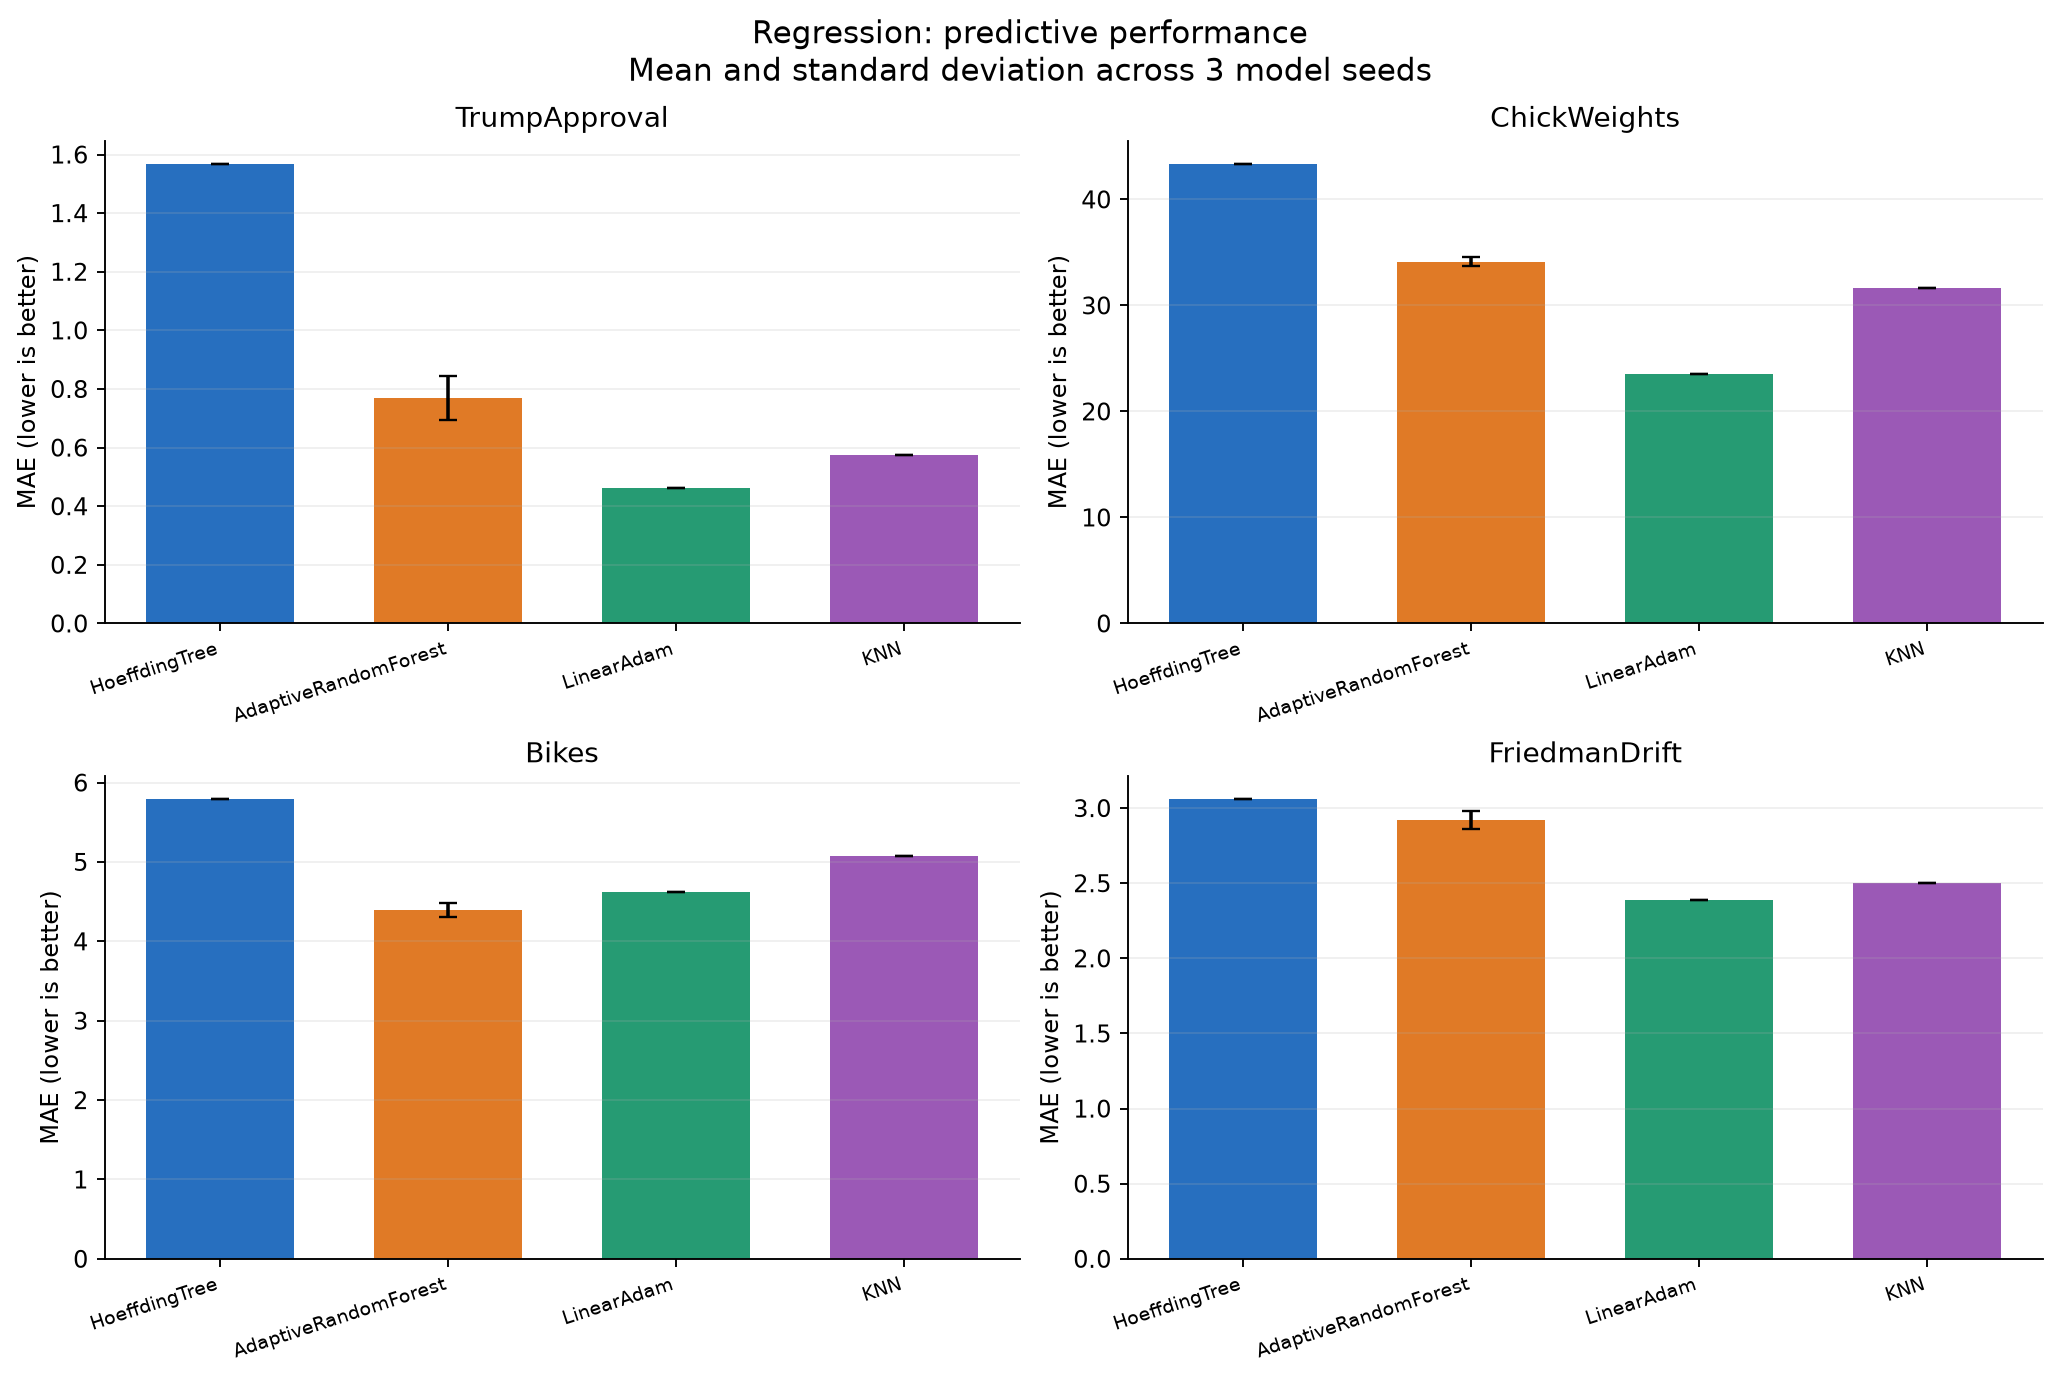

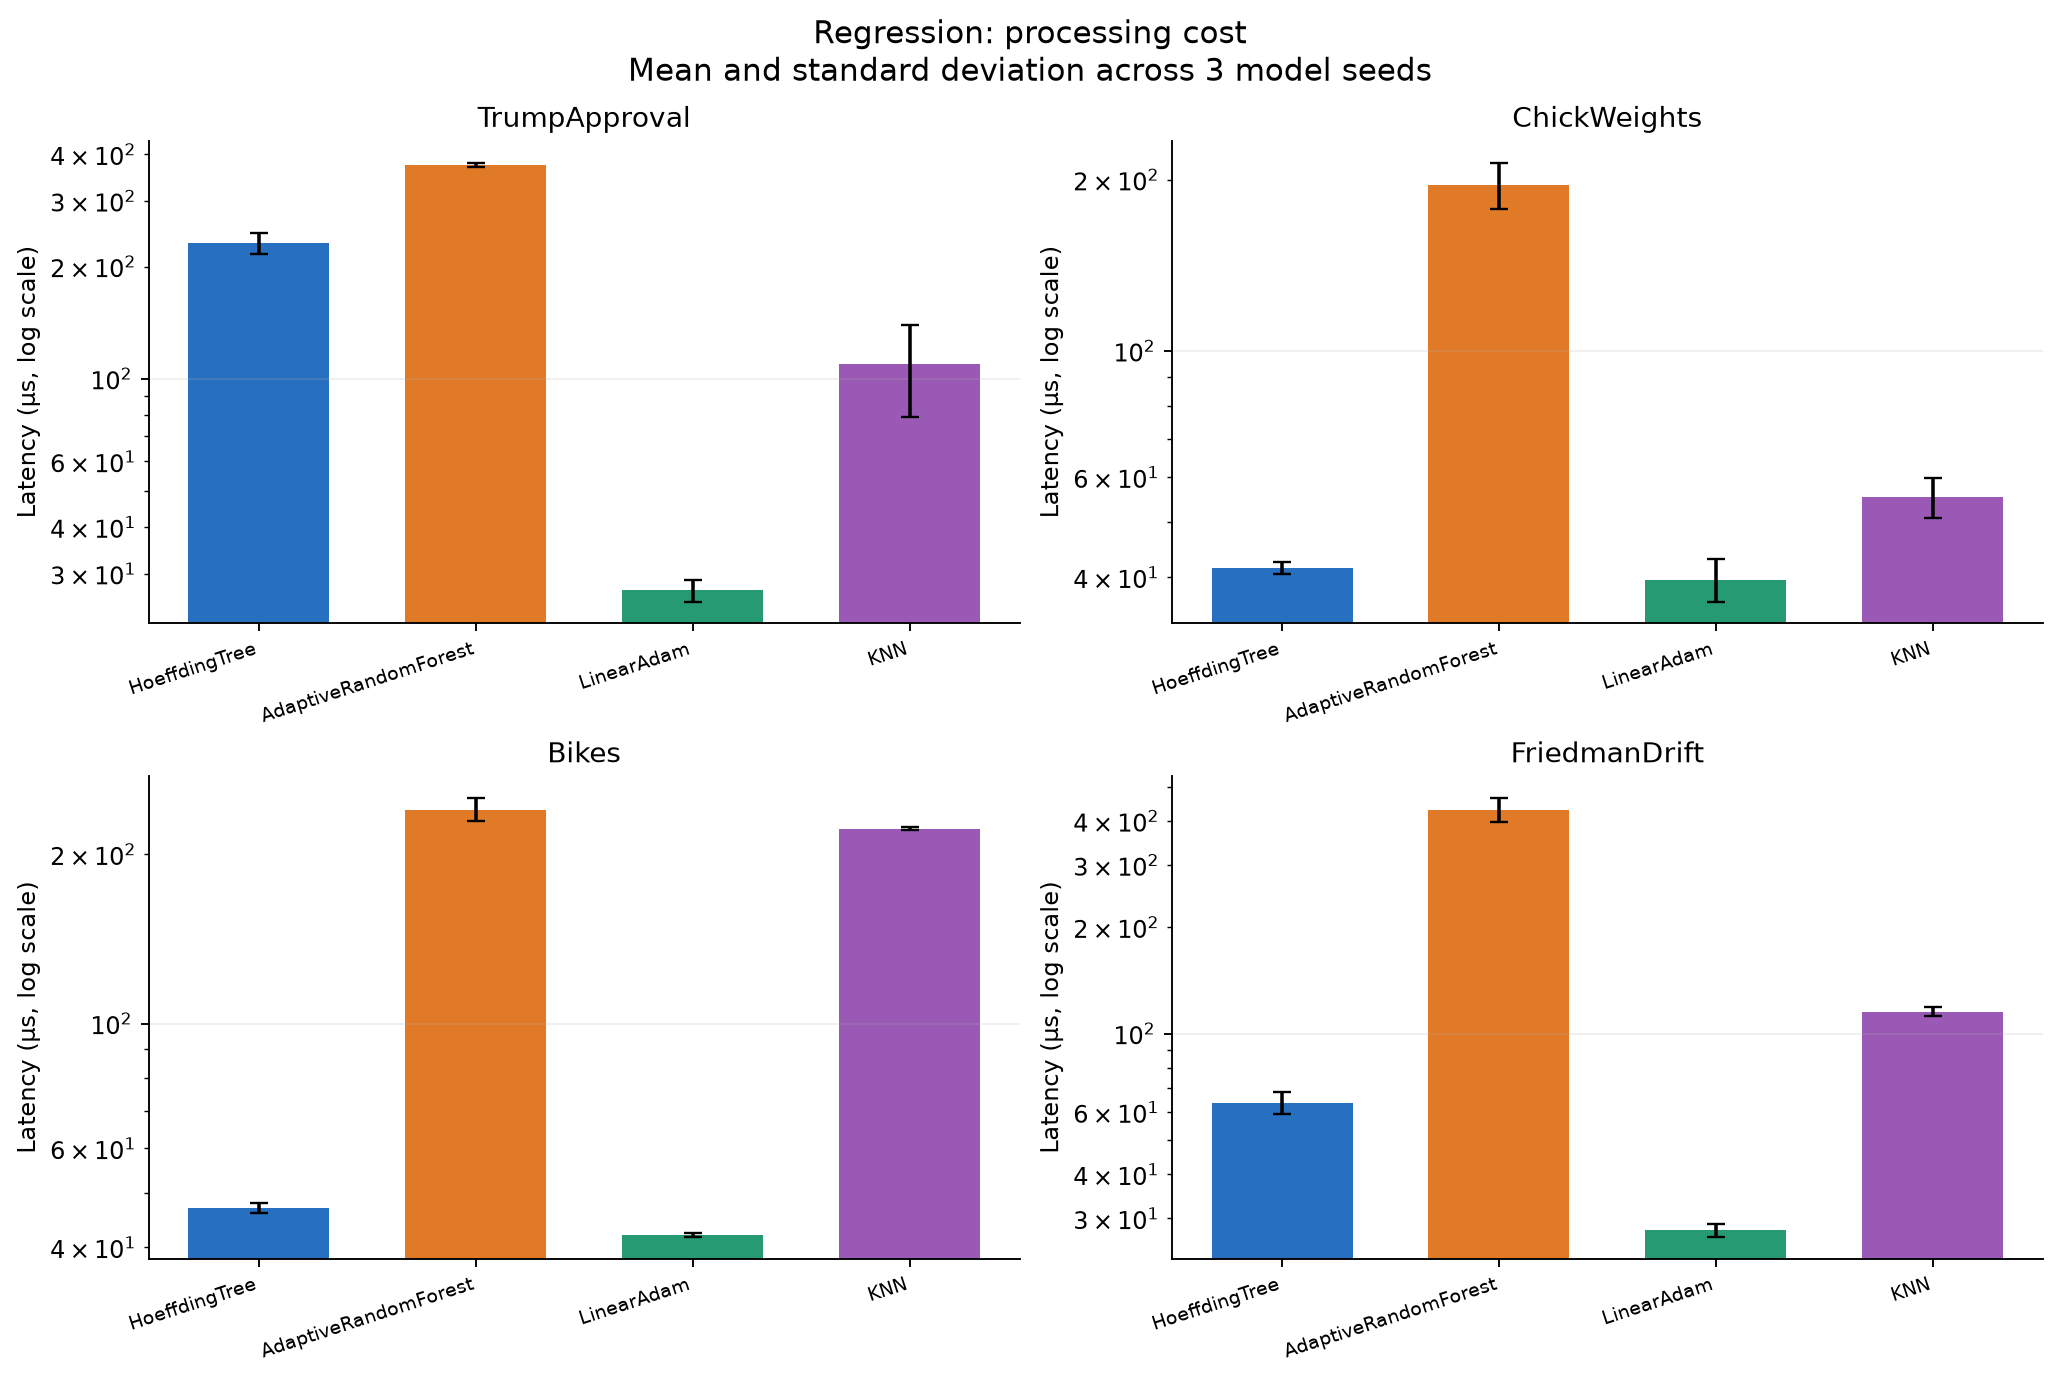

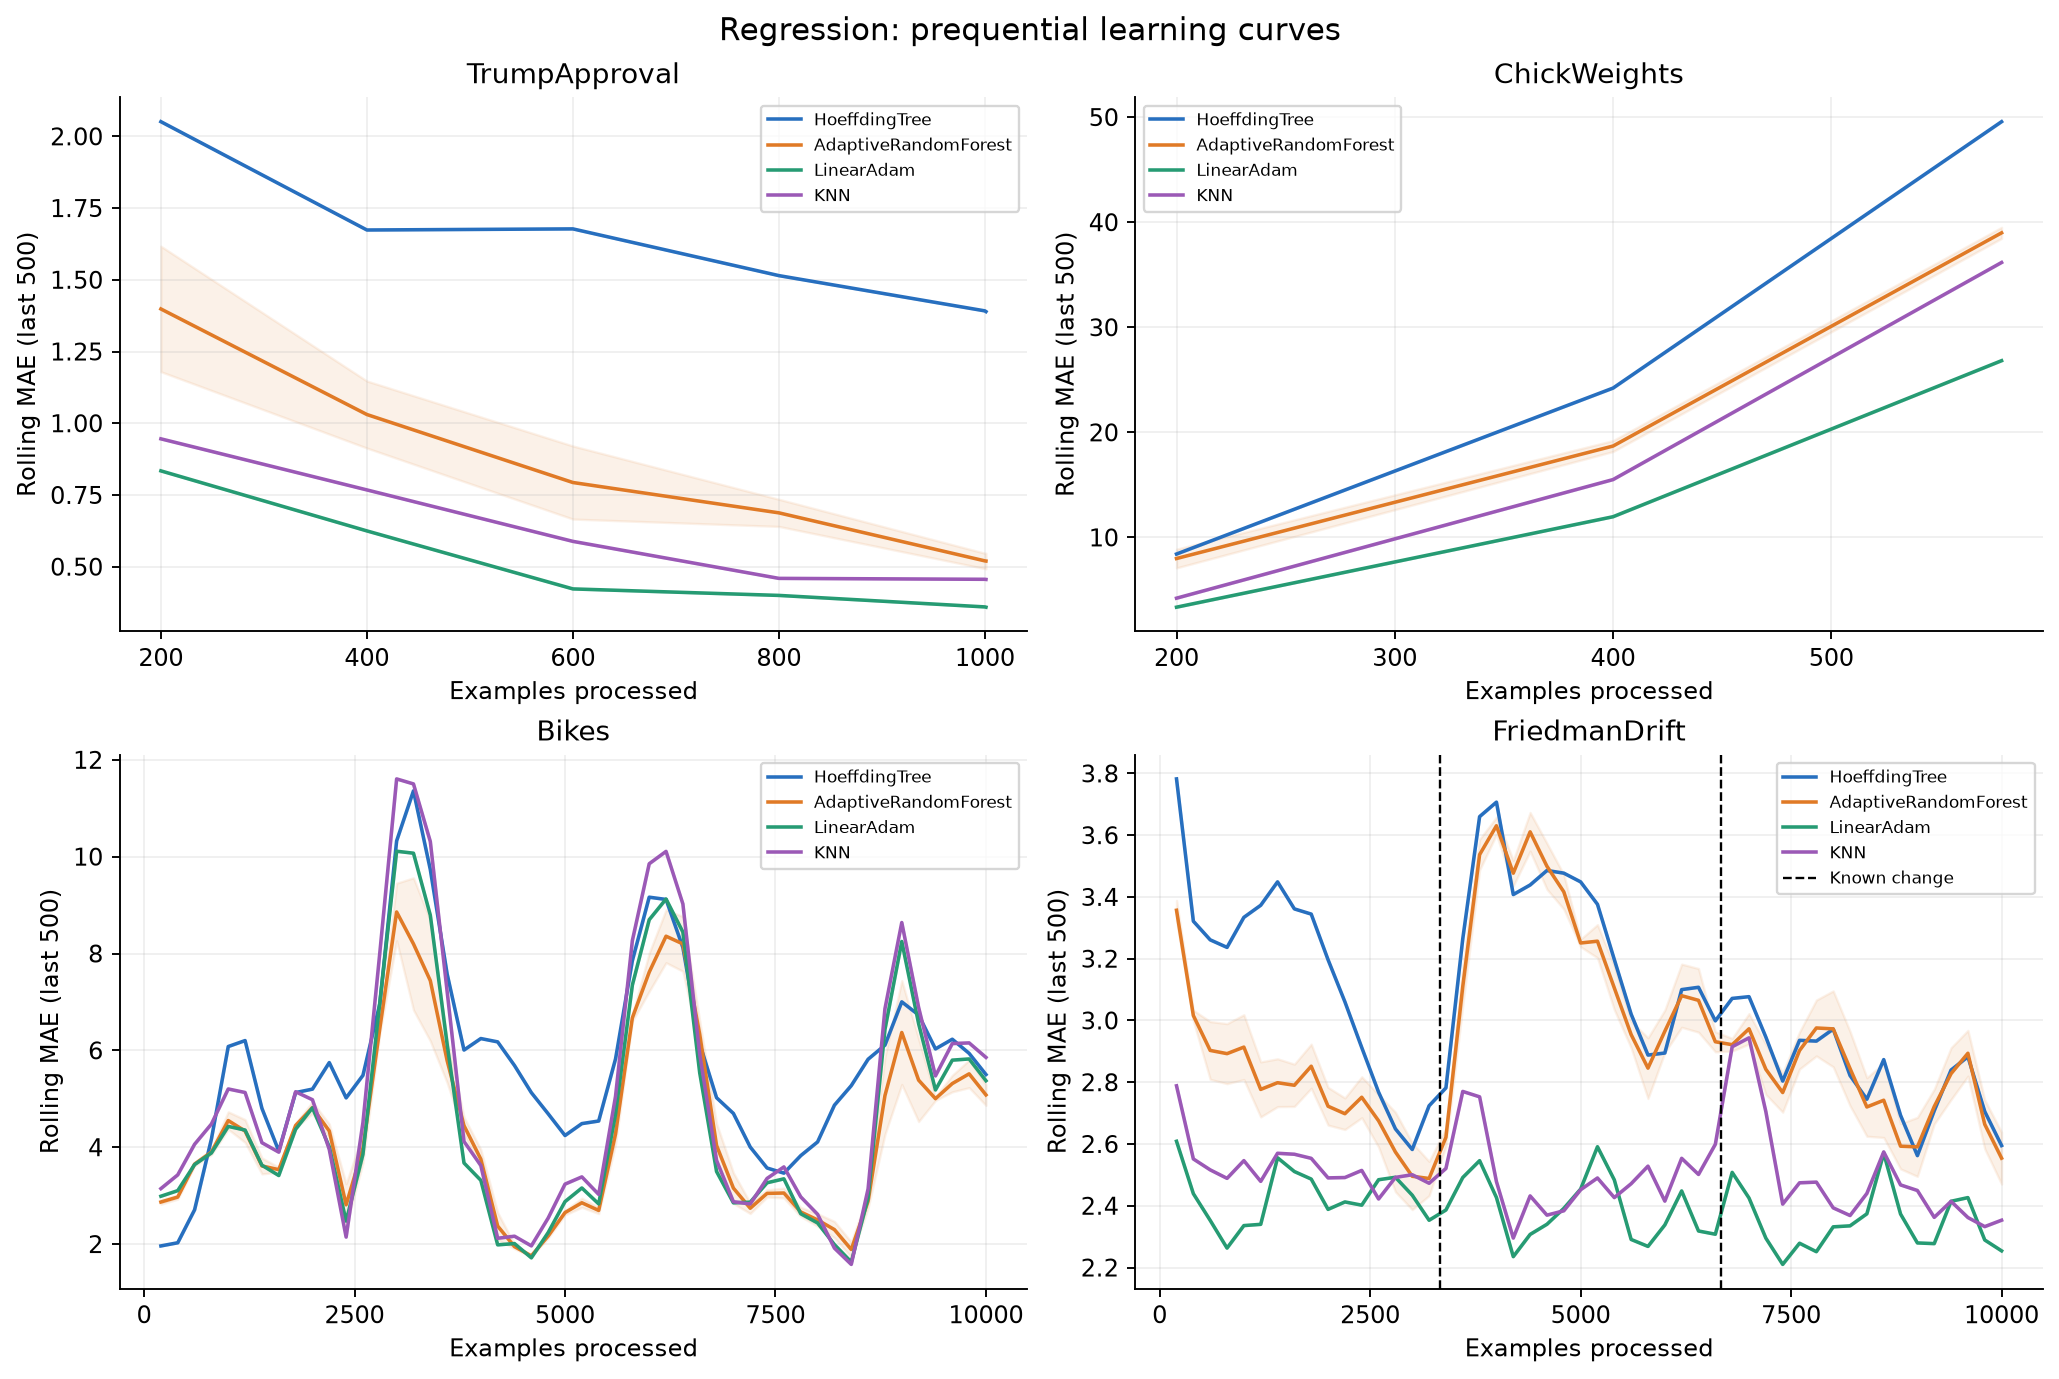

In [5]:
regression = pd.read_csv(OUT / "regression_metrics.csv")
regression_means = regression.groupby(["dataset", "model"], sort=False)[["mae", "rmse", "r2", "mean_latency_us", "p95_latency_us", "total_runtime_s", "sampled_peak_process_rss_mb"]].mean().reset_index()
display(regression_means)
for filename in ["regression_performance", "regression_latency", "regression_learning_curves"]:
    display(Image(filename=str(FIG / f"{filename}.png")))


## Step 4 — Regression drift detection and handling

ADWIN, Page-Hinkley and KSWIN first replay identical ordinary-HT test-then-train errors without changing that model. Separate alarm-triggered tree-reset experiments measure whether handling improves prediction.

The regression signal is absolute error divided by three times past-target SD, with SD at least one and the result clipped to [0,1]. The first 200 samples are predicted/learned but withheld from external detectors. ADWIN delta=0.002; Page-Hinkley threshold=10; KSWIN alpha=0.005. Complete settings are in the model module.

FriedmanDrift changes at zero-based indices **3333 and 6666**. Each true change matches the first unused alarm within 1500 index steps. Misses and unmatched alarms are explicit; missed changes do not receive zero delay. Real streams have no verified drift positions.

,dataset,detector,n_alarms,matched_changes,missed_changes,unmatched_alarms,mean_delay,detector_only_runtime_s
0,TrumpApproval,ADWIN,1.0000,NaN,NaN,NaN,NaN,0.0005
1,TrumpApproval,PageHinkley,2.0000,NaN,NaN,NaN,NaN,0.0006
2,TrumpApproval,KSWIN,7.0000,NaN,NaN,NaN,NaN,0.0169
3,ChickWeights,ADWIN,0.0000,NaN,NaN,NaN,NaN,0.0002
4,ChickWeights,PageHinkley,0.0000,NaN,NaN,NaN,NaN,0.0004
5,ChickWeights,KSWIN,2.3333,NaN,NaN,NaN,NaN,0.0324
6,Bikes,ADWIN,11.0000,NaN,NaN,NaN,NaN,0.0030
7,Bikes,PageHinkley,26.0000,NaN,NaN,NaN,NaN,0.0085
8,Bikes,KSWIN,70.3333,NaN,NaN,NaN,NaN,1.0539
9,FriedmanDrift,ADWIN,3.0000,2.0000,0.0000,1.0000,335.5000,0.0034


Seed 42 alarms (complete positions are also in drift_events.csv):


,dataset,detector,alarm_positions,matches
72,TrumpApproval,ADWIN,[487],[]
73,TrumpApproval,PageHinkley,"[476, 710]",[]
74,TrumpApproval,KSWIN,"[300, 400, 501, 602, 702, 828, 928]",[]
81,ChickWeights,ADWIN,[],[]
82,ChickWeights,PageHinkley,[],[]
83,ChickWeights,KSWIN,"[299, 421, 561]",[]
90,Bikes,ADWIN,"[615, 871, 1223, 1735, 2407, 3367, 4711, 5511,...",[]
91,Bikes,PageHinkley,"[405, 595, 807, 970, 1203, 1463, 1699, 1820, 2...",[]
92,Bikes,KSWIN,"[320, 453, 564, 664, 779, 898, 998, 1115, 1229...",[]
99,FriedmanDrift,ADWIN,"[2599, 3559, 7111]","[{""true_position"": 3333, ""detected_position"": ..."


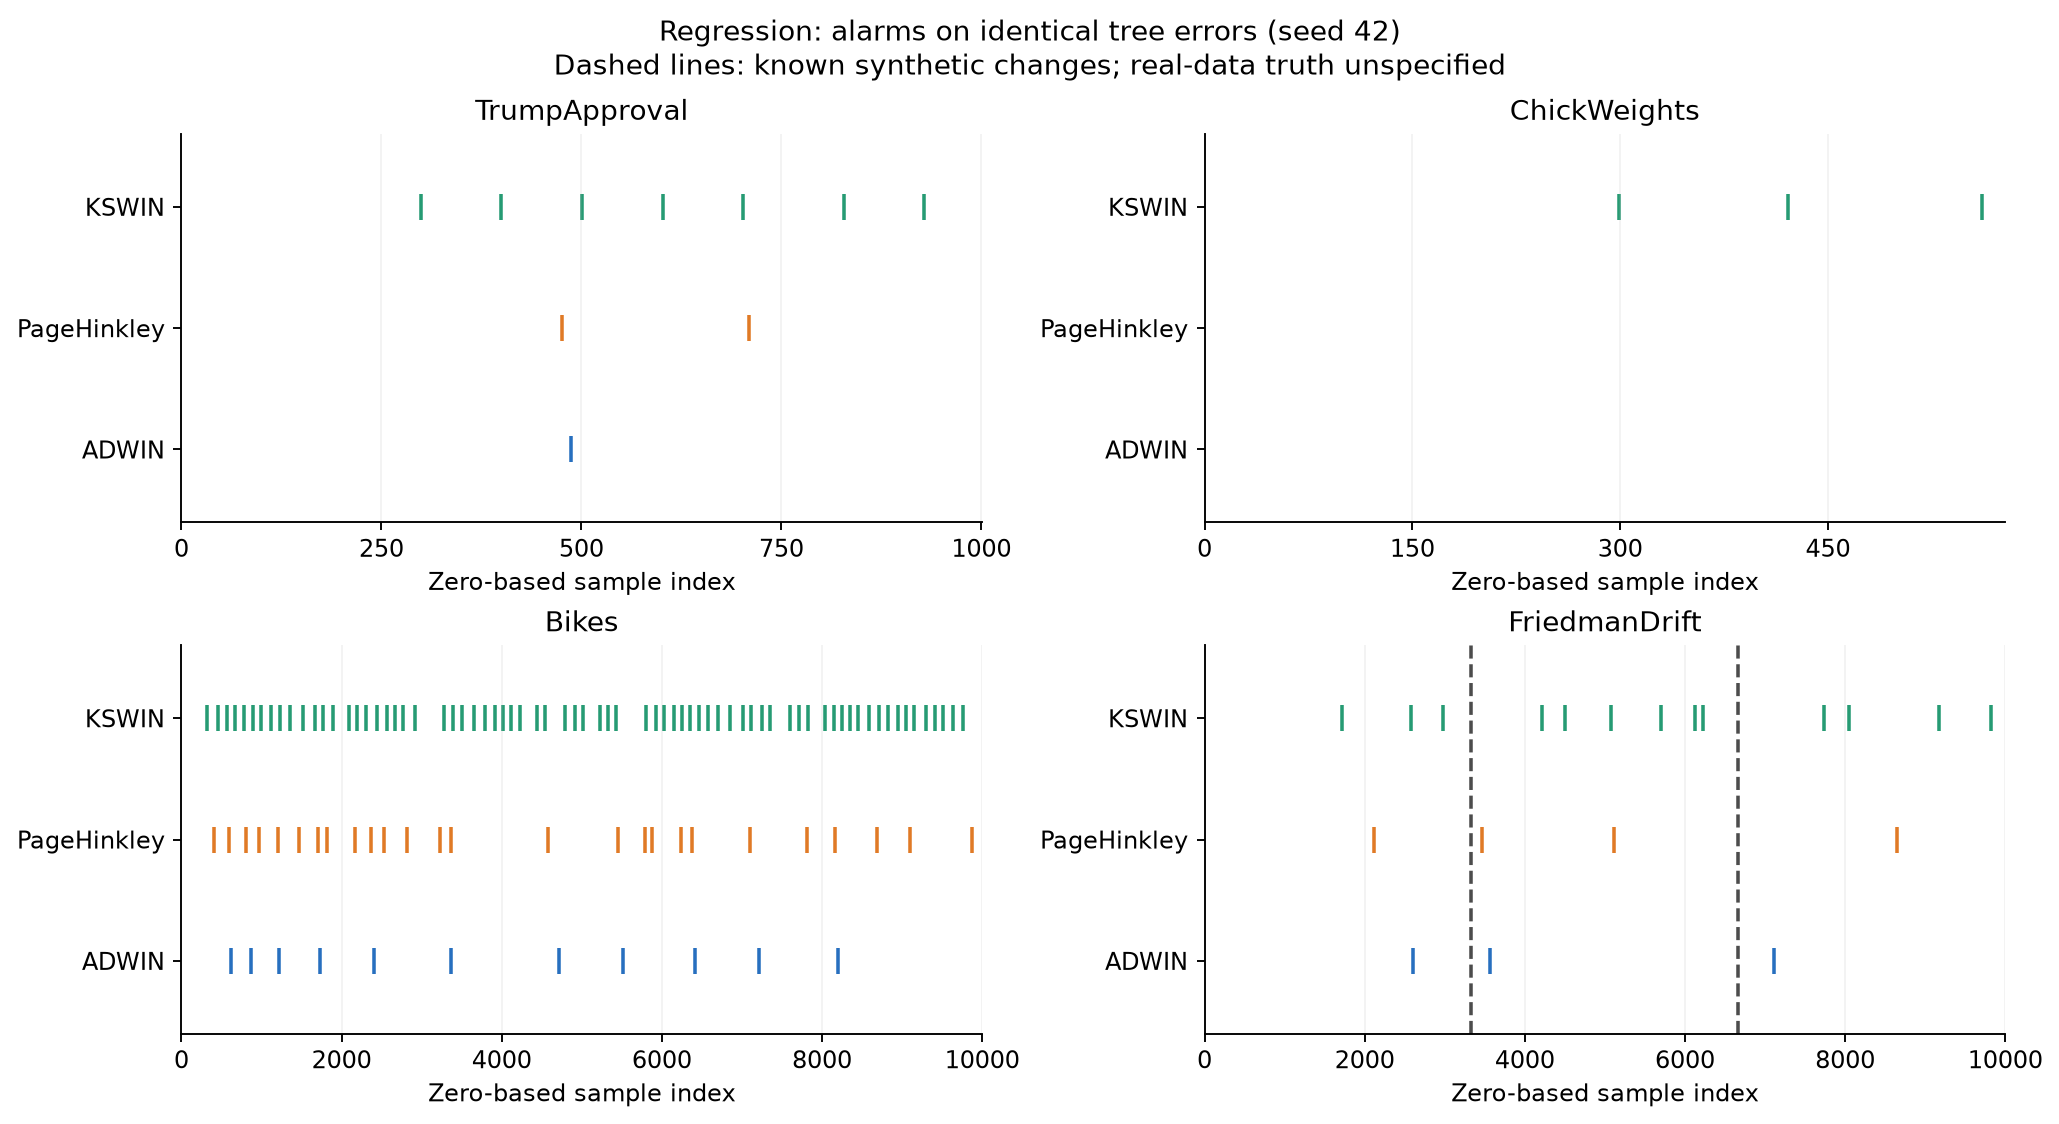

,task,dataset,detector_reset,mae_change_mean,mae_change_std,latency_ratio_mean,latency_ratio_std
0,regression,TrumpApproval,ADWIN,-0.4191,0.0000,0.4877,0.0289
1,regression,TrumpApproval,PageHinkley,-0.4188,0.0000,0.4394,0.0188
2,regression,TrumpApproval,KSWIN,-0.5816,0.0019,0.4279,0.0078
3,regression,ChickWeights,ADWIN,0.0000,0.0000,1.1074,0.0998
4,regression,ChickWeights,PageHinkley,0.0000,0.0000,1.0515,0.0880
5,regression,ChickWeights,KSWIN,-12.8811,0.0864,3.8685,0.0998
6,regression,Bikes,ADWIN,-1.6244,0.0000,0.7777,0.0185
7,regression,Bikes,PageHinkley,-1.7457,0.0000,0.7628,0.0193
8,regression,Bikes,KSWIN,-1.4974,0.0402,2.4996,0.0905
9,regression,FriedmanDrift,ADWIN,0.2594,0.0000,0.9691,0.0032


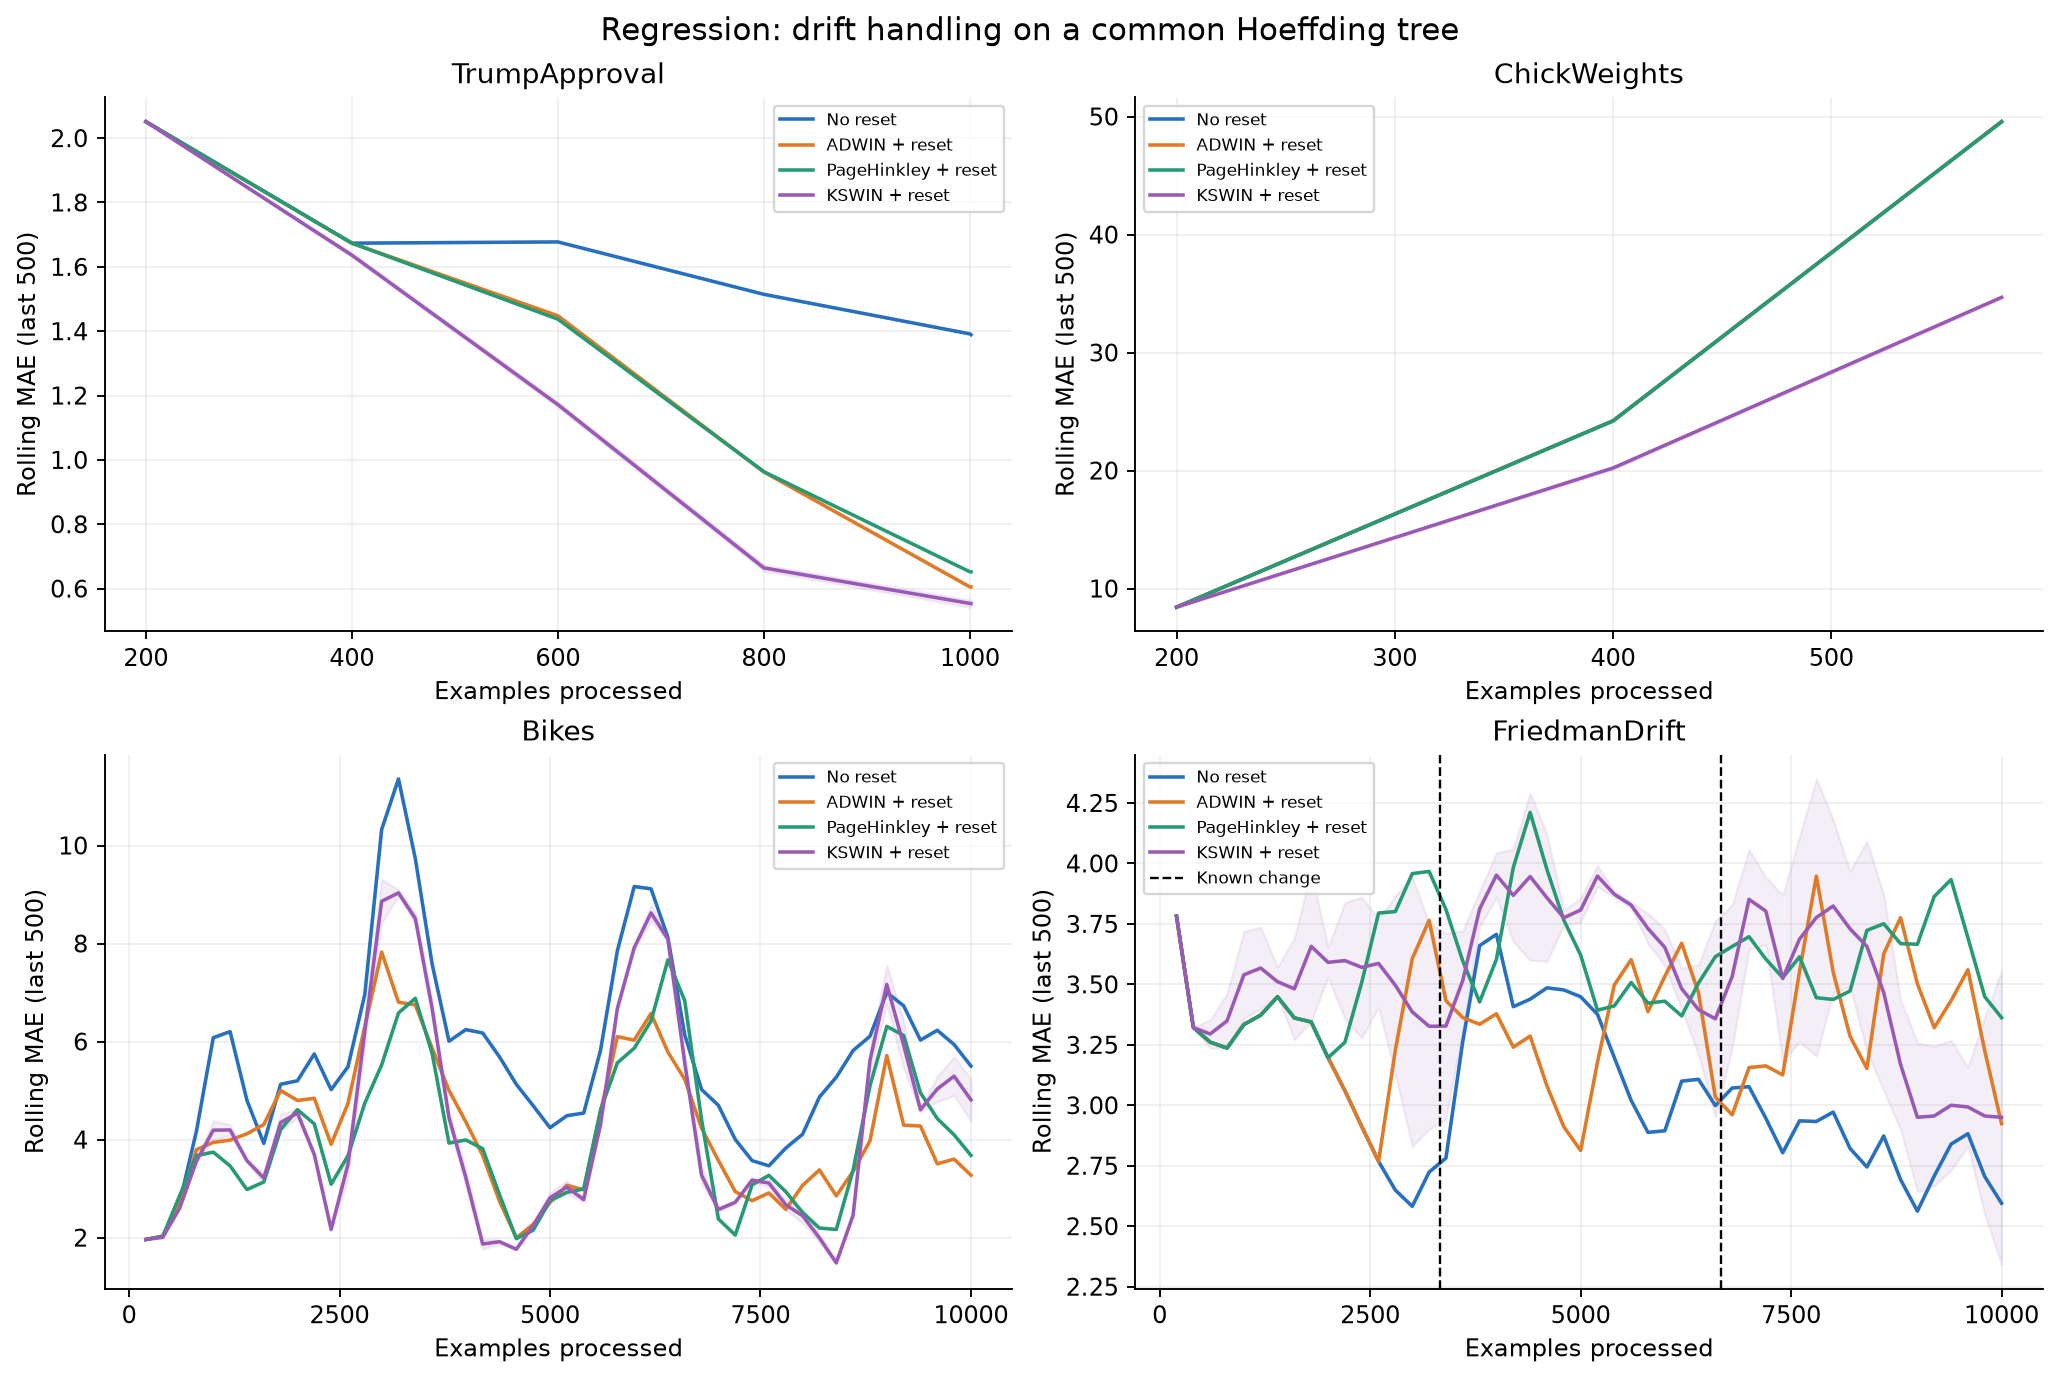

,dataset,model,mode,detector,change_position,window,score
0,FriedmanDrift,HoeffdingTree,baseline,none,3333,before,2.5929
1,FriedmanDrift,HoeffdingTree,baseline,none,3333,immediate_after,3.7518
2,FriedmanDrift,HoeffdingTree,baseline,none,3333,recovery,3.4437
3,FriedmanDrift,HoeffdingTree,baseline,none,6666,before,3.0281
4,FriedmanDrift,HoeffdingTree,baseline,none,6666,immediate_after,2.9693
5,FriedmanDrift,HoeffdingTree,baseline,none,6666,recovery,2.7901
6,FriedmanDrift,HoeffdingTree,reset,ADWIN,3333,before,3.4624
7,FriedmanDrift,HoeffdingTree,reset,ADWIN,3333,immediate_after,3.3676
8,FriedmanDrift,HoeffdingTree,reset,ADWIN,3333,recovery,2.8997
9,FriedmanDrift,HoeffdingTree,reset,ADWIN,6666,before,2.9760


In [6]:
drifts = pd.read_csv(OUT / "drift_summary.csv")
events = pd.read_csv(OUT / "drift_events.csv")
regression_detection = drifts[(drifts.task == "regression") & (drifts["mode"] == "monitor")]
display(regression_detection.groupby(["dataset", "detector"], sort=False)[["n_alarms", "matched_changes", "missed_changes", "unmatched_alarms", "mean_delay", "detector_only_runtime_s"]].mean().reset_index())
print("Seed 42 alarms (complete positions are also in drift_events.csv):")
display(regression_detection.loc[regression_detection.seed == 42, ["dataset", "detector", "alarm_positions", "matches"]])
display(Image(filename=str(FIG / "regression_drift_alarms.png")))

effects = pd.read_csv(OUT / "reset_effect_summary.csv")
display(effects[effects.task == "regression"].dropna(axis=1, how="all"))
display(Image(filename=str(FIG / "regression_reset_effect.png")))

windows = pd.read_csv(OUT / "recovery_windows.csv")
display(windows[(windows.task == "regression") & (windows.model == "HoeffdingTree")].groupby(["dataset", "model", "mode", "detector", "change_position", "window"], sort=False).score.mean().reset_index())


## Step 5 — Classification: repeat method, dataset and drift comparisons

| Family | Method | Principal settings |
| --- | --- | --- |
| Tree | HoeffdingTreeClassifier | Grace period 100; depth 12; adaptive-NB leaves |
| Ensemble | ARFClassifier | Five trees; depth 12; internal ADWIN |
| Adaptive linear | Adam LogisticRegression + OneVsRestClassifier | Rate 0.01; online scaling; multiclass support |
| Other | GaussianNB | Gaussian naive Bayes |

Real data: **Elec2, Phishing and ImageSegments**. ImageSegments has seven classes. Report accuracy, Macro-F1, Cohen's kappa and costs. Phishing and ImageSegments use static file order; alarms are not verified real-time concept changes.

**SEARecurring** uses SEA variant 0 with 5% label noise. Labels invert from index 3333 and return at 6666; the feature distribution stays unchanged. ADWIN, DDM and EDDM receive the model's 0/1 prediction errors.

,dataset,kind,n_samples,original_n_samples,encoded_n_features,class_labels,known_drift_positions
4,Elec2,real,10000,45312,14,"[False, True]",[]
5,Phishing,real,1250,1250,9,"[False, True]",[]
6,ImageSegments,real,2310,2310,18,"[brickface, cement, foliage, grass, path, sky,...",[]
7,SEARecurring,synthetic,10000,10000,3,"[False, True]","[3333, 6666]"



HoeffdingTree
HoeffdingTreeClassifier (
  grace_period=100
  max_depth=12
  split_criterion="info_gain"
  delta=1e-07
  tau=0.05
  leaf_prediction="nba"
  nb_threshold=0
  nominal_attributes=None
  splitter=GaussianSplitter (
    n_splits=10
  )
  binary_split=False
  min_branch_fraction=0.01
  max_share_to_split=0.99
  max_size=64
  memory_estimate_period=1000000
  stop_mem_management=False
  remove_poor_attrs=False
  merit_preprune=True
)

AdaptiveRandomForest
[]

LogisticAdamOvR
Pipeline (
  StandardScaler (
    with_std=True
    window_size=None
  ),
  OneVsRestClassifier (
    classifier=LogisticRegression (
      optimizer=Adam (
        lr=Constant (
          learning_rate=0.01
        )
        beta_1=0.9
        beta_2=0.999
        eps=1e-08
      )
      loss=Log (
        weight_pos=1.
        weight_neg=1.
      )
      l2=0.
      l1=0.
      intercept_init=0.
      intercept_lr=Constant (
        learning_rate=0.01
      )
      clip_gradient=1e+12
      initializer=Ze

,dataset,model,accuracy,macro_f1,kappa,mean_latency_us,p95_latency_us,total_runtime_s,sampled_peak_process_rss_mb
0,Elec2,HoeffdingTree,0.8545,0.8511,0.7023,53.0026,78.9067,0.5989,151.5951
1,Elec2,AdaptiveRandomForest,0.8758,0.8731,0.7462,358.4207,600.1981,3.6661,153.2930
2,Elec2,LogisticAdamOvR,0.8508,0.8471,0.6943,45.1398,49.8540,0.5148,153.2943
3,Elec2,GaussianNB,0.7940,0.7802,0.5667,132.9459,149.5999,1.4128,153.2982
4,Phishing,HoeffdingTree,0.8752,0.8734,0.7468,52.5289,53.9332,0.0733,154.5065
5,Phishing,AdaptiveRandomForest,0.8899,0.8880,0.7759,337.0464,576.9435,0.4309,154.6172
6,Phishing,LogisticAdamOvR,0.8984,0.8973,0.7948,50.1982,87.0987,0.0709,154.6211
7,Phishing,GaussianNB,0.8840,0.8828,0.7656,141.6537,189.5849,0.1874,154.6211
8,ImageSegments,HoeffdingTree,0.7779,0.7664,0.7409,212.3812,255.9818,0.5079,154.7812
9,ImageSegments,AdaptiveRandomForest,0.7491,0.7465,0.7072,604.6413,1001.5296,1.4167,154.9193


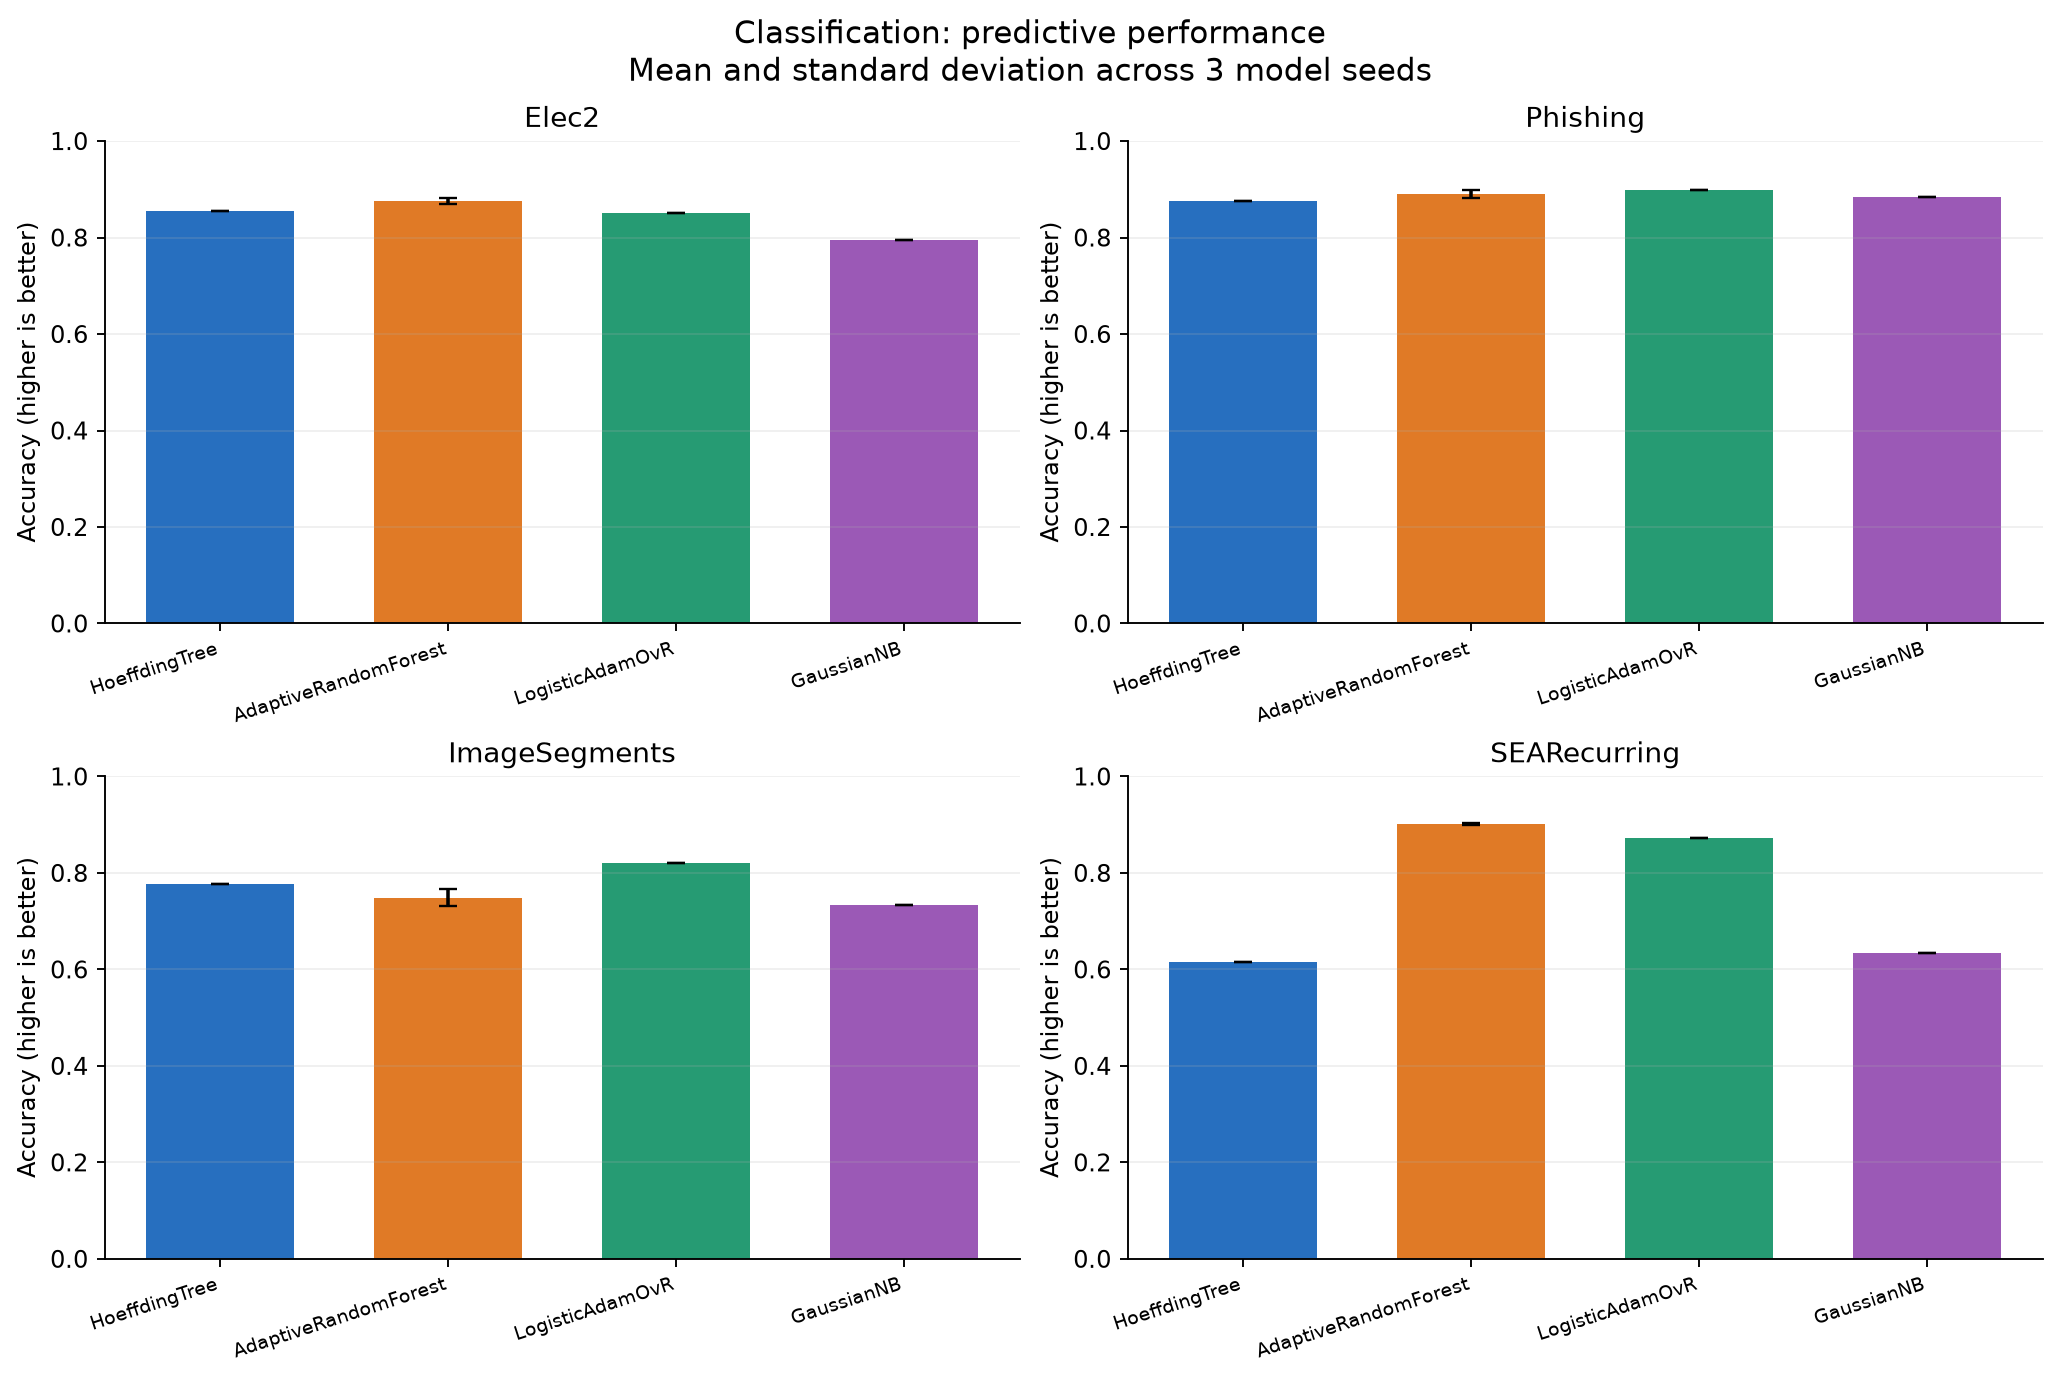

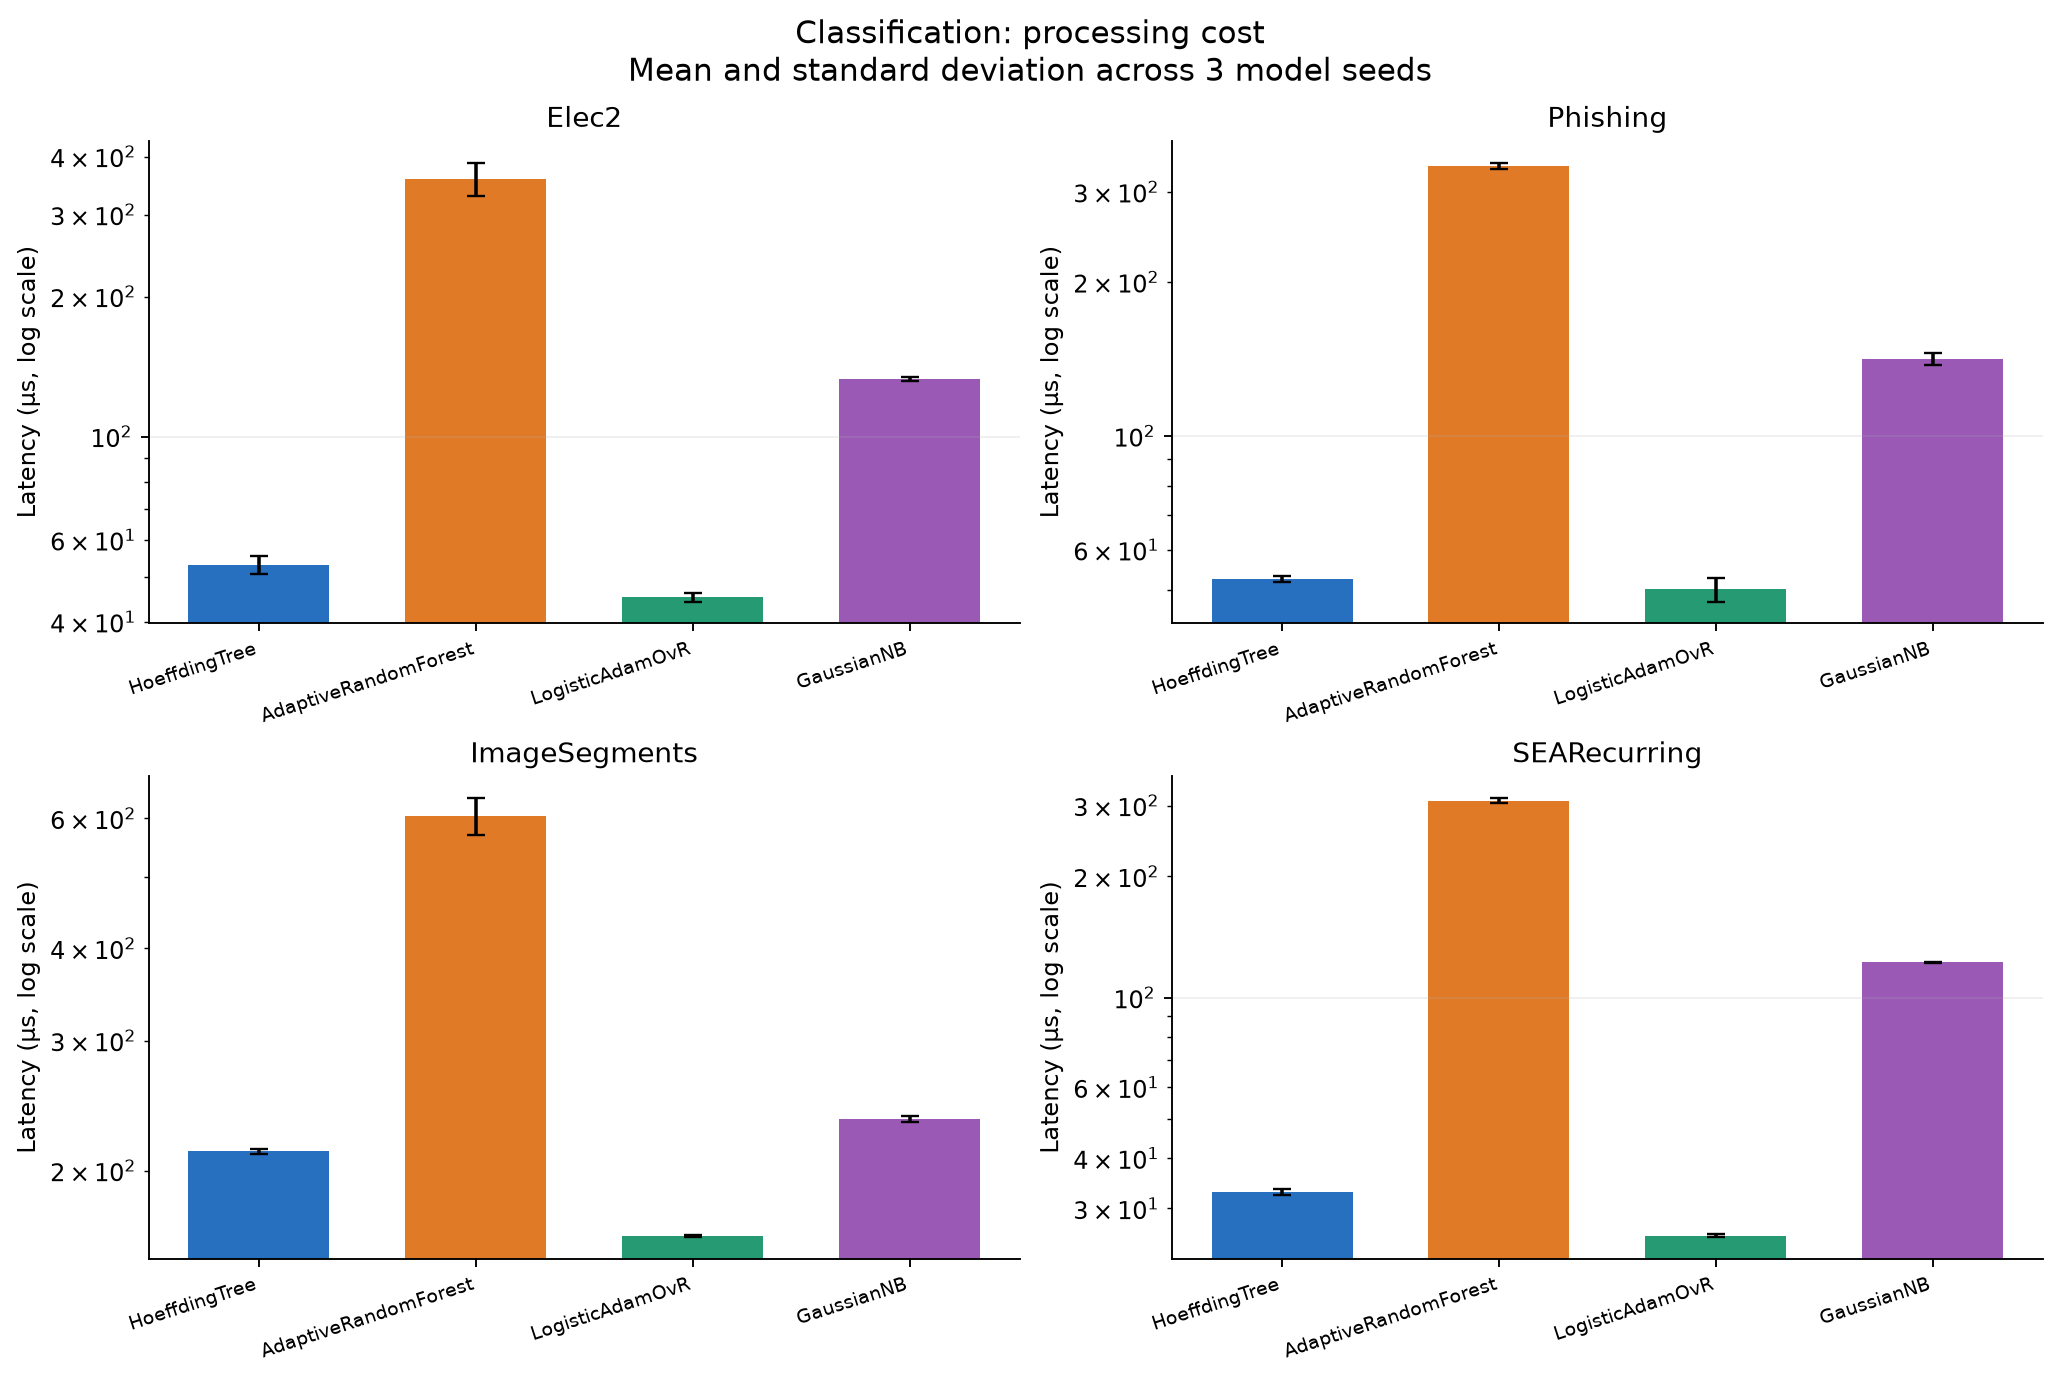

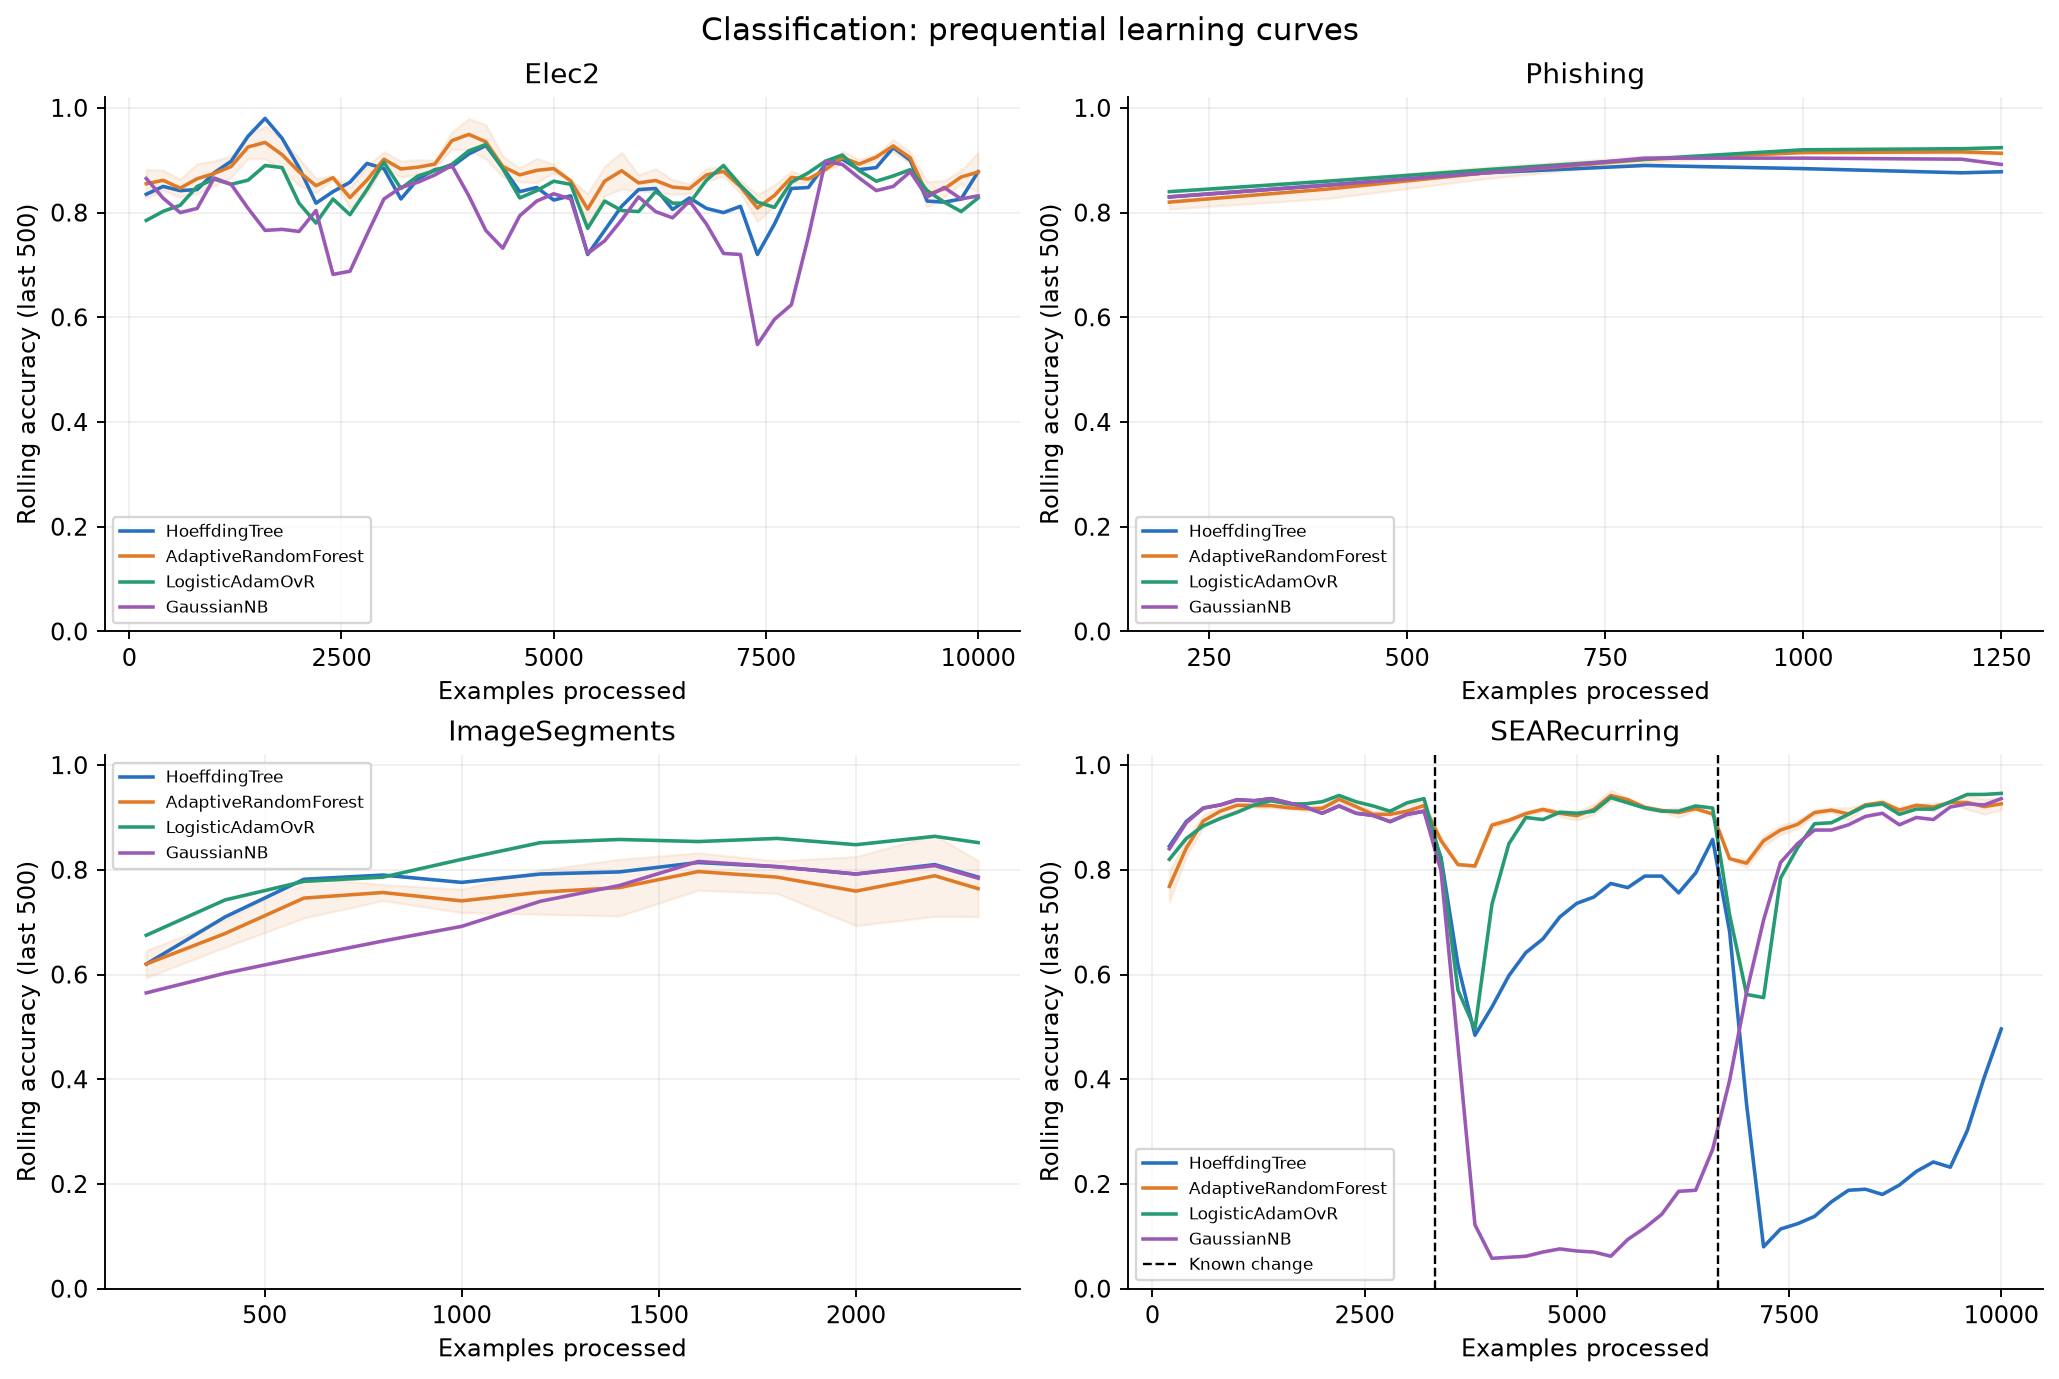

In [7]:
display(data_table.loc[data_table.task == "classification", ["dataset", "kind", "n_samples", "original_n_samples", "encoded_n_features", "class_labels", "known_drift_positions"]])
classification_models = {name: make_model("classification", name, 42, config) for name in CLASSIFICATION_MODELS}
for name, model in classification_models.items():
    print(f"\n{name}\n{model!r}")

classification = pd.read_csv(OUT / "classification_metrics.csv")
classification_means = classification.groupby(["dataset", "model"], sort=False)[["accuracy", "macro_f1", "kappa", "mean_latency_us", "p95_latency_us", "total_runtime_s", "sampled_peak_process_rss_mb"]].mean().reset_index()
display(classification_means)
for filename in ["classification_performance", "classification_latency", "classification_learning_curves"]:
    display(Image(filename=str(FIG / f"{filename}.png")))


,dataset,detector,n_alarms,matched_changes,missed_changes,unmatched_alarms,mean_delay,detector_only_runtime_s
0,Elec2,ADWIN,8.0000,NaN,NaN,NaN,NaN,0.0032
1,Elec2,DDM,18.0000,NaN,NaN,NaN,NaN,0.0063
2,Elec2,EDDM,42.0000,NaN,NaN,NaN,NaN,0.0038
3,Phishing,ADWIN,0.0000,NaN,NaN,NaN,NaN,0.0003
4,Phishing,DDM,0.0000,NaN,NaN,NaN,NaN,0.0007
5,Phishing,EDDM,3.0000,NaN,NaN,NaN,NaN,0.0004
6,ImageSegments,ADWIN,0.0000,NaN,NaN,NaN,NaN,0.0006
7,ImageSegments,DDM,0.0000,NaN,NaN,NaN,NaN,0.0014
8,ImageSegments,EDDM,1.0000,NaN,NaN,NaN,NaN,0.0009
9,SEARecurring,ADWIN,6.0000,2.0000,0.0000,4.0000,31.5000,0.0030


Seed 42 alarms:


,dataset,detector,alarm_positions,matches
108,Elec2,ADWIN,"[1415, 1831, 4135, 5383, 5799, 7239, 7591, 9287]",[]
109,Elec2,DDM,"[345, 408, 593, 1805, 2017, 2132, 2215, 2444, ...",[]
110,Elec2,EDDM,"[407, 604, 868, 1138, 1800, 2028, 2145, 2443, ...",[]
117,Phishing,ADWIN,[],[]
118,Phishing,DDM,[],[]
119,Phishing,EDDM,"[464, 766, 998]",[]
126,ImageSegments,ADWIN,[],[]
127,ImageSegments,DDM,[],[]
128,ImageSegments,EDDM,[532],[]
135,SEARecurring,ADWIN,"[3367, 4423, 6535, 6695, 8711, 9703]","[{""true_position"": 3333, ""detected_position"": ..."


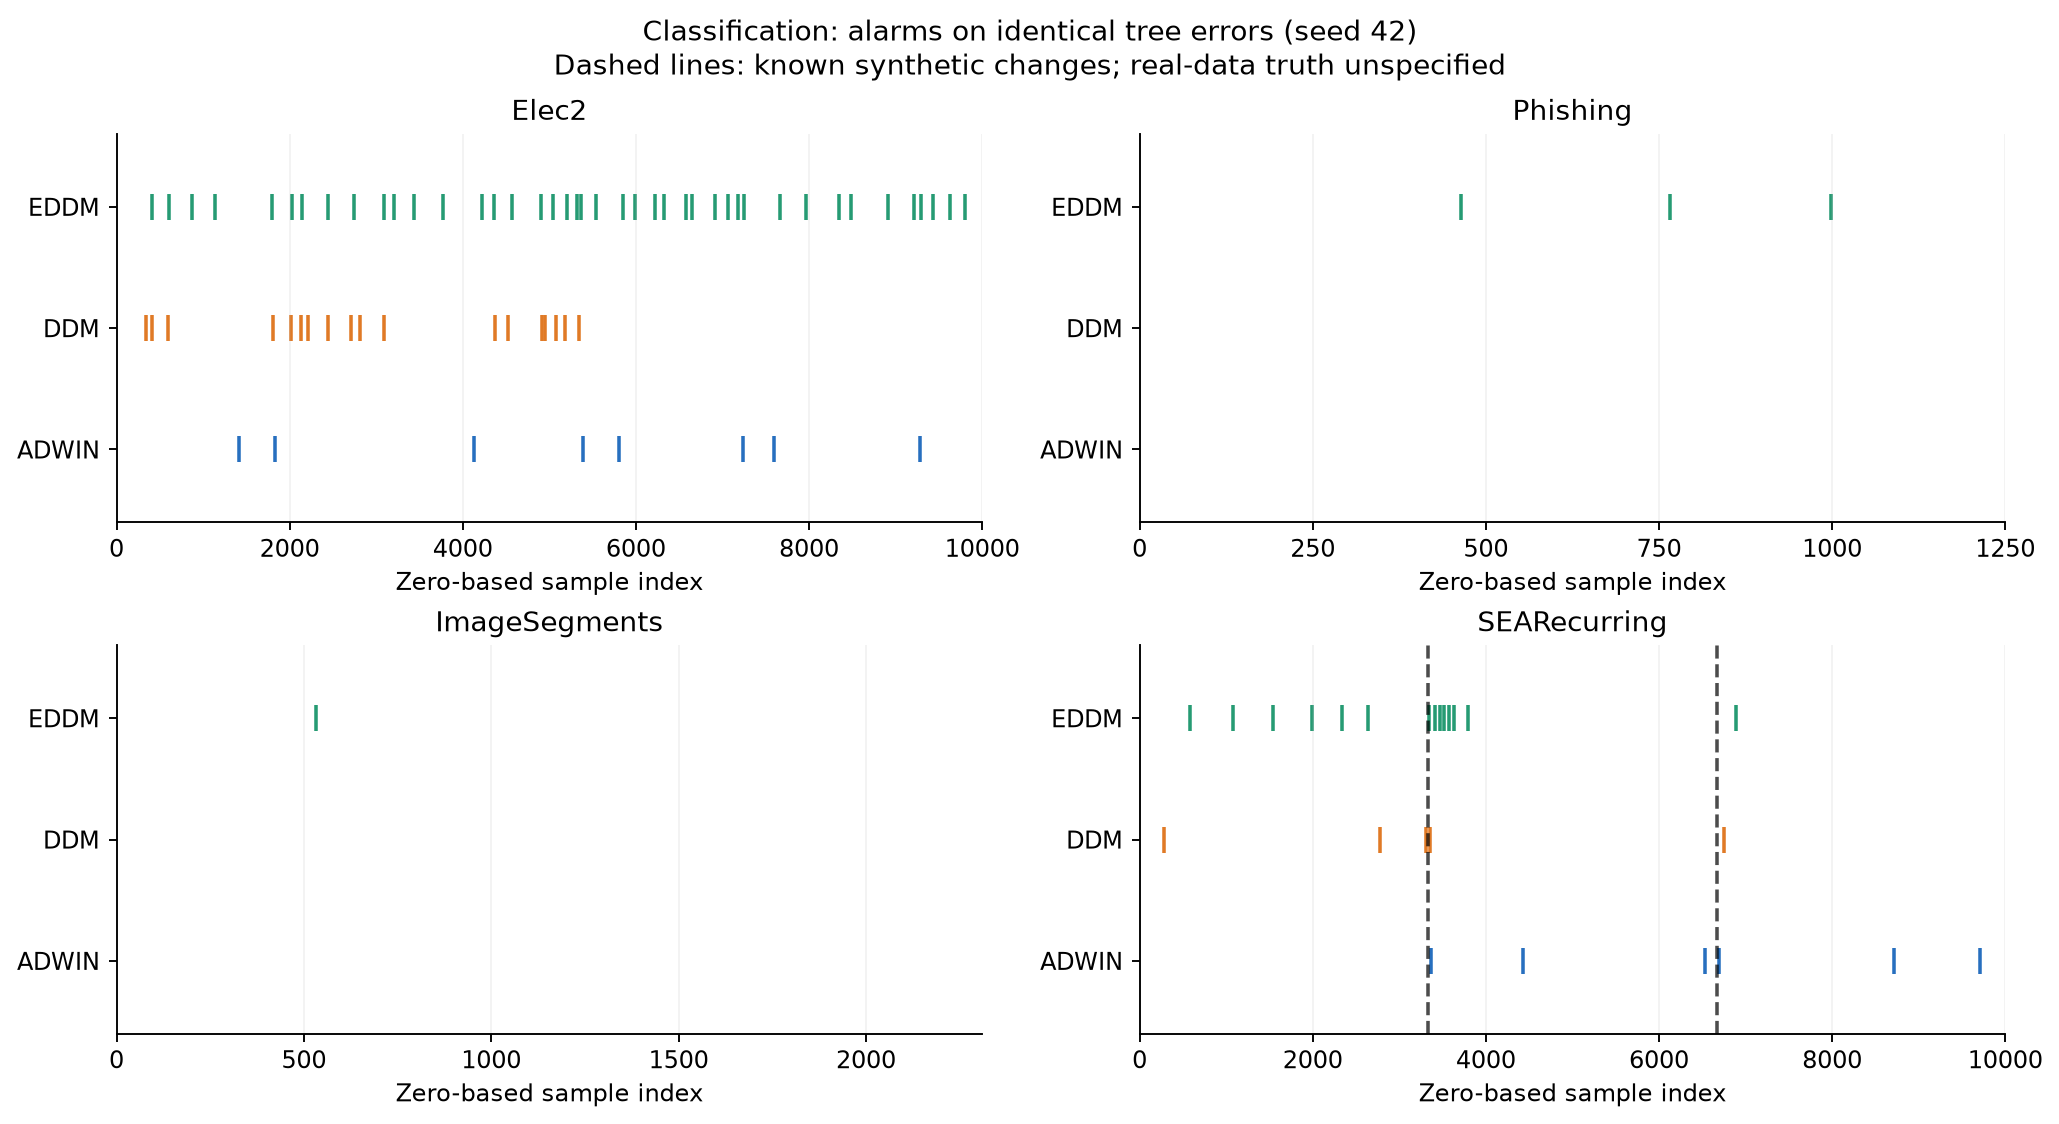

,task,dataset,detector_reset,accuracy_change_mean,accuracy_change_std,latency_ratio_mean,latency_ratio_std
12,classification,Elec2,ADWIN,0.0249,0.0000,0.9684,0.0508
13,classification,Elec2,DDM,0.0380,0.0000,0.9920,0.0529
14,classification,Elec2,EDDM,0.0308,0.0000,0.9972,0.0606
15,classification,Phishing,ADWIN,0.0000,0.0000,1.0351,0.0124
16,classification,Phishing,DDM,0.0000,0.0000,1.0563,0.0161
17,classification,Phishing,EDDM,-0.0048,0.0000,1.1103,0.0214
18,classification,ImageSegments,ADWIN,0.0000,0.0000,0.9982,0.0112
19,classification,ImageSegments,DDM,0.0000,0.0000,1.0073,0.0153
20,classification,ImageSegments,EDDM,-0.0152,0.0000,1.0144,0.0072
21,classification,SEARecurring,ADWIN,0.2887,0.0000,0.9645,0.0123


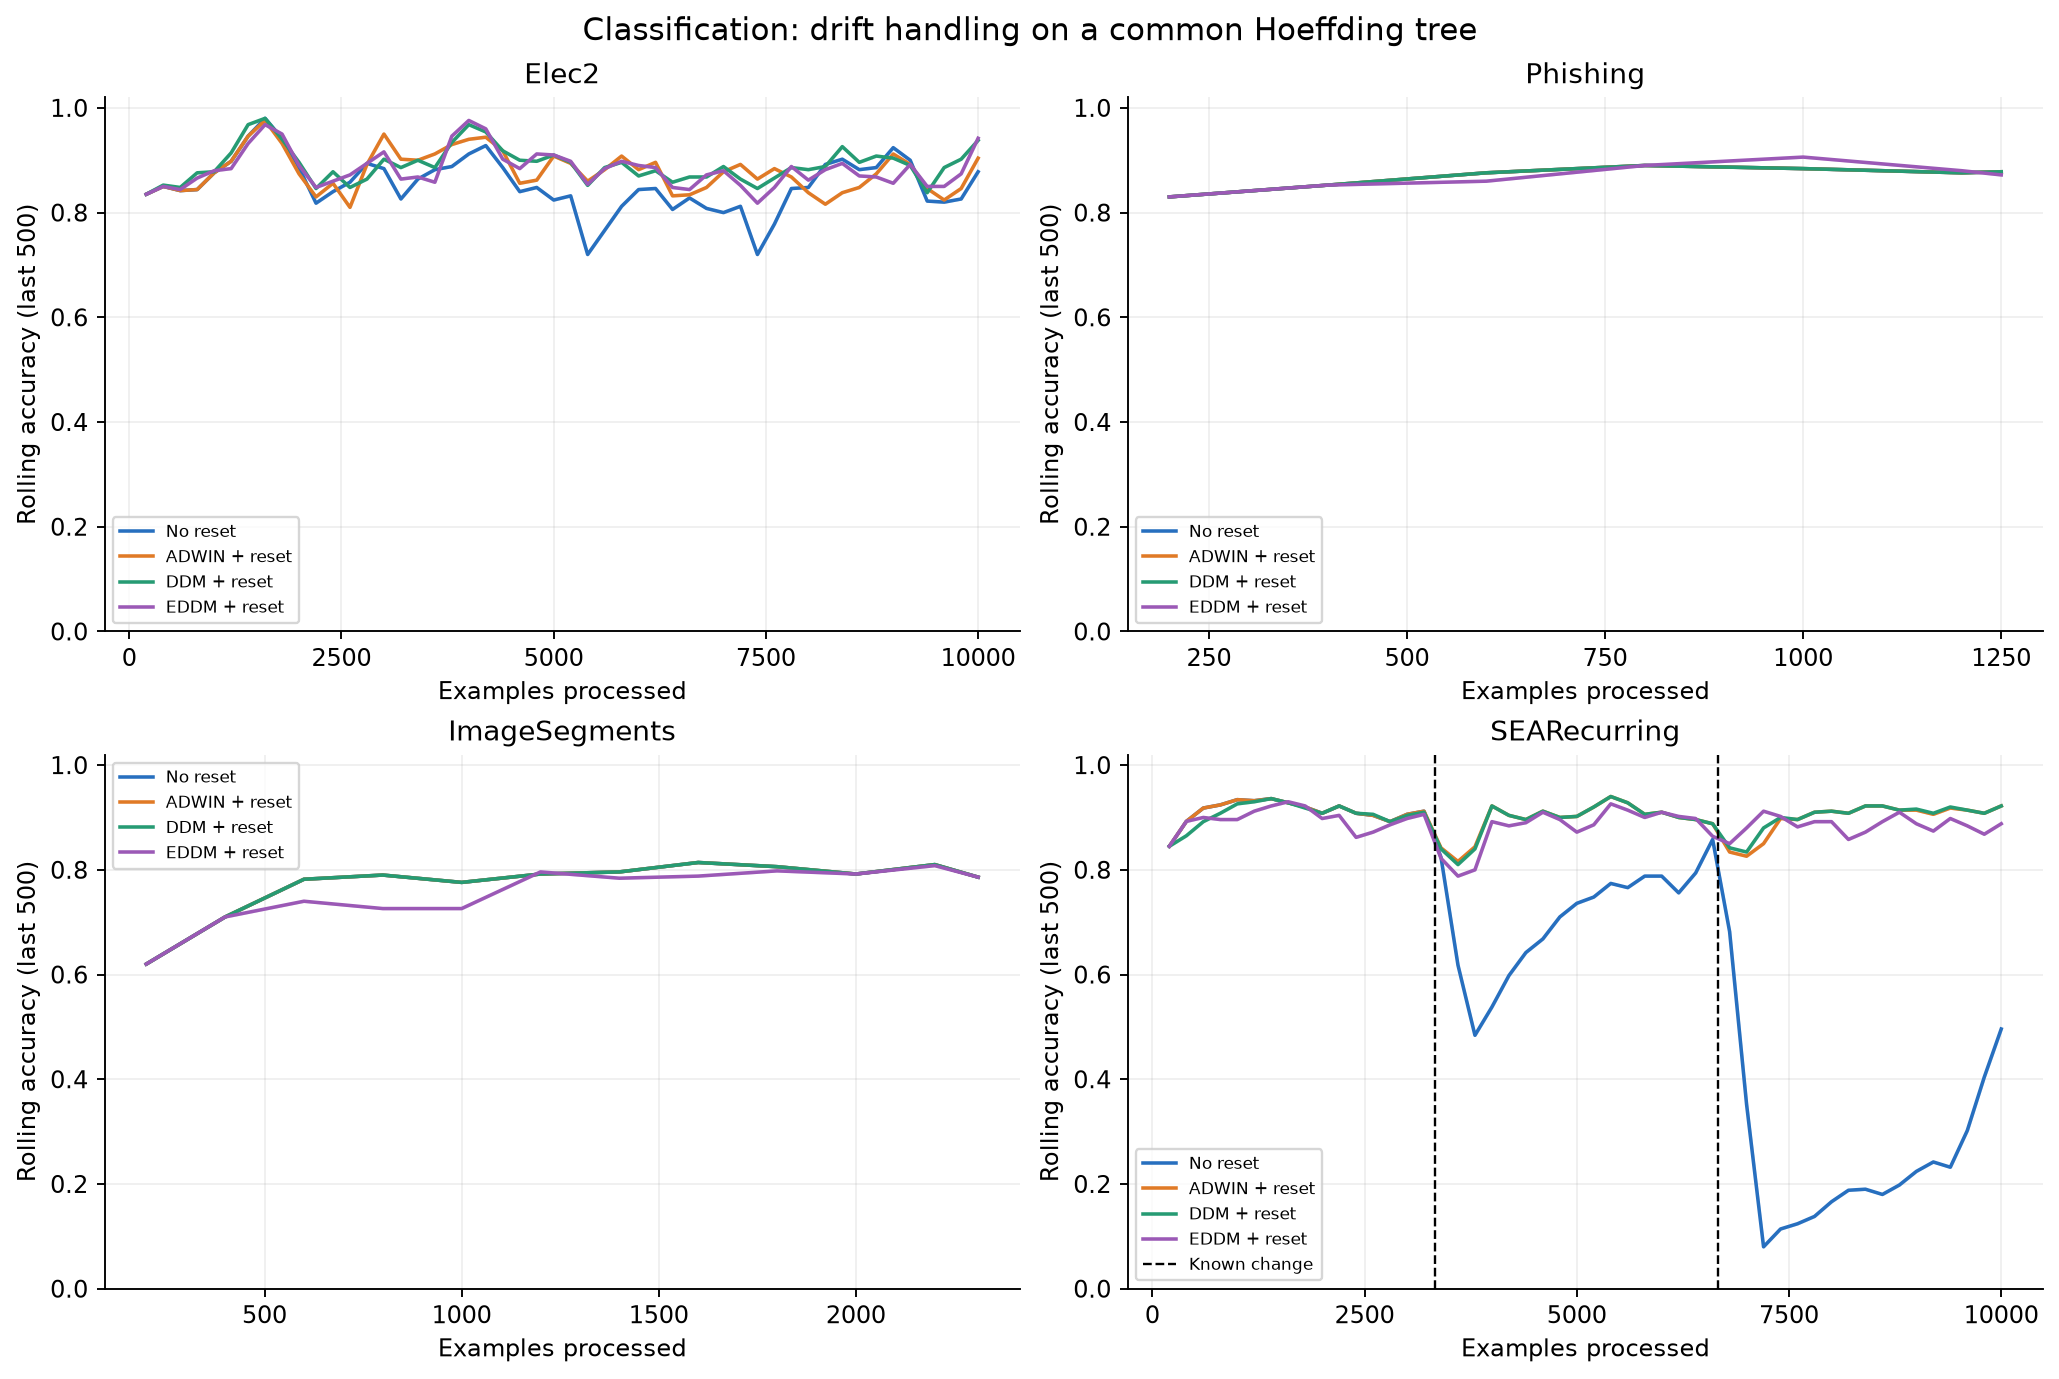

,dataset,model,mode,detector,change_position,window,score
0,SEARecurring,HoeffdingTree,baseline,none,3333,before,0.9100
1,SEARecurring,HoeffdingTree,baseline,none,3333,immediate_after,0.4540
2,SEARecurring,HoeffdingTree,baseline,none,3333,recovery,0.7140
3,SEARecurring,HoeffdingTree,baseline,none,6666,before,0.8860
4,SEARecurring,HoeffdingTree,baseline,none,6666,immediate_after,0.0820
5,SEARecurring,HoeffdingTree,baseline,none,6666,recovery,0.1920
6,SEARecurring,HoeffdingTree,reset,ADWIN,3333,before,0.9100
7,SEARecurring,HoeffdingTree,reset,ADWIN,3333,immediate_after,0.8460
8,SEARecurring,HoeffdingTree,reset,ADWIN,3333,recovery,0.9000
9,SEARecurring,HoeffdingTree,reset,ADWIN,6666,before,0.8940


In [8]:
classification_detection = drifts[(drifts.task == "classification") & (drifts["mode"] == "monitor")]
display(classification_detection.groupby(["dataset", "detector"], sort=False)[["n_alarms", "matched_changes", "missed_changes", "unmatched_alarms", "mean_delay", "detector_only_runtime_s"]].mean().reset_index())
print("Seed 42 alarms:")
display(classification_detection.loc[classification_detection.seed == 42, ["dataset", "detector", "alarm_positions", "matches"]])
display(Image(filename=str(FIG / "classification_drift_alarms.png")))
display(effects[effects.task == "classification"].dropna(axis=1, how="all"))
display(Image(filename=str(FIG / "classification_reset_effect.png")))
display(windows[(windows.task == "classification") & (windows.model == "HoeffdingTree")].groupby(["dataset", "model", "mode", "detector", "change_position", "window"], sort=False).score.mean().reset_index())


## Result validation and analysis

The next cell checks completed combinations, sample counts, valid metrics and consistent alarms. The English analysis covers quality/cost trade-offs, missed changes, reset effects and experimental limits.

In [9]:
validation = json.loads((OUT / "validation.json").read_text())
assert all(validation.values()), validation
display(pd.DataFrame(validation.items(), columns=["check", "passed"]))
display(Markdown((OUT / "findings.md").read_text()))


,check,passed
0,all_regression_baselines_present,True
1,all_classification_baselines_present,True
2,all_reset_comparisons_present,True
3,all_detector_comparisons_present,True
4,all_runs_have_finite_metrics,True
5,classification_scores_in_bounds,True
6,all_alarms_accounted_for,True
7,all_experiments_marked_complete,True
8,identical_sample_counts_for_each_dataset,True
9,all_seed_model_combinations_unique,True


# River: measured results and analysis

168 model runs and 72 detector-only replays use model seeds 42, 43 and 44, with synthetic generation seed 2026. Each observation is predicted and scored before detection/reset and learning. All methods use the same ordered caches.

## Setup and scope

Regression families are an ordinary Hoeffding tree, a five-tree adaptive random forest, scaled Adam linear regression and scaled KNN (k=5, FIFO window 300). Classification uses the tree, forest, scaled one-vs-rest Adam logistic regression and Gaussian naive Bayes. The Part 1 trees have depth limit 12. Input scaling and regression target scaling update online; categorical encoding is stateless.

Bikes and Elec2 use their first 10,000 observations. Smaller real datasets are used in full; both synthetic streams contain 10,000 examples. Phishing and ImageSegments are static benchmarks without verified chronological order. The three model seeds share one stream realization: their SDs are not independent-stream confidence intervals.

## Regression performance

| dataset | model | mae | rmse | r2 | mean_latency_us | total_runtime_s |
| --- | --- | --- | --- | --- | --- | --- |
| TrumpApproval | HoeffdingTree | 1.5676 | 2.2029 | -0.6585 | 231.5967 | 0.2396 |
| TrumpApproval | AdaptiveRandomForest | 0.7700 | 1.8216 | -0.1541 | 375.0721 | 0.3870 |
| TrumpApproval | LinearAdam | 0.4635 | 1.5000 | 0.2310 | 27.0338 | 0.0342 |
| TrumpApproval | KNN | 0.5732 | 1.5527 | 0.1760 | 109.2790 | 0.1180 |
| ChickWeights | HoeffdingTree | 43.3367 | 64.3950 | 0.1776 | 41.5457 | 0.0280 |
| ChickWeights | AdaptiveRandomForest | 34.1241 | 52.5184 | 0.4529 | 195.7920 | 0.1195 |
| ChickWeights | LinearAdam | 23.5474 | 38.3797 | 0.7079 | 39.6085 | 0.0271 |
| ChickWeights | KNN | 31.6657 | 53.0822 | 0.4412 | 55.3277 | 0.0358 |
| Bikes | HoeffdingTree | 5.7878 | 7.4937 | 0.0306 | 46.9756 | 0.5444 |
| Bikes | AdaptiveRandomForest | 4.3955 | 5.9012 | 0.3987 | 240.2791 | 2.5254 |
| Bikes | LinearAdam | 4.6185 | 6.4336 | 0.2855 | 42.0985 | 0.5002 |
| Bikes | KNN | 5.0774 | 7.5720 | 0.0103 | 222.3014 | 2.3141 |
| FriedmanDrift | HoeffdingTree | 3.0577 | 3.8409 | 0.4030 | 63.6656 | 0.7089 |
| FriedmanDrift | AdaptiveRandomForest | 2.9220 | 3.6490 | 0.4611 | 430.1993 | 4.4243 |
| FriedmanDrift | LinearAdam | 2.3880 | 3.0644 | 0.6200 | 27.7467 | 0.3459 |
| FriedmanDrift | KNN | 2.5032 | 3.1399 | 0.6011 | 115.4009 | 1.2399 |

- TrumpApproval: best mean mae: LinearAdam (0.4635); fastest: LinearAdam (27.03 µs/item). The best-quality model costs 1.00 times the lowest mean latency.
- ChickWeights: best mean mae: LinearAdam (23.5474); fastest: LinearAdam (39.61 µs/item). The best-quality model costs 1.00 times the lowest mean latency.
- Bikes: best mean mae: AdaptiveRandomForest (4.3955); fastest: LinearAdam (42.10 µs/item). The best-quality model costs 5.71 times the lowest mean latency.
- FriedmanDrift: best mean mae: LinearAdam (2.3880); fastest: LinearAdam (27.75 µs/item). The best-quality model costs 1.00 times the lowest mean latency.

## Classification performance

| dataset | model | accuracy | macro_f1 | kappa | mean_latency_us | total_runtime_s |
| --- | --- | --- | --- | --- | --- | --- |
| Elec2 | HoeffdingTree | 0.8545 | 0.8511 | 0.7023 | 53.0026 | 0.5989 |
| Elec2 | AdaptiveRandomForest | 0.8758 | 0.8731 | 0.7462 | 358.4207 | 3.6661 |
| Elec2 | LogisticAdamOvR | 0.8508 | 0.8471 | 0.6943 | 45.1398 | 0.5148 |
| Elec2 | GaussianNB | 0.7940 | 0.7802 | 0.5667 | 132.9459 | 1.4128 |
| Phishing | HoeffdingTree | 0.8752 | 0.8734 | 0.7468 | 52.5289 | 0.0733 |
| Phishing | AdaptiveRandomForest | 0.8899 | 0.8880 | 0.7759 | 337.0464 | 0.4309 |
| Phishing | LogisticAdamOvR | 0.8984 | 0.8973 | 0.7948 | 50.1982 | 0.0709 |
| Phishing | GaussianNB | 0.8840 | 0.8828 | 0.7656 | 141.6537 | 0.1874 |
| ImageSegments | HoeffdingTree | 0.7779 | 0.7664 | 0.7409 | 212.3812 | 0.5079 |
| ImageSegments | AdaptiveRandomForest | 0.7491 | 0.7465 | 0.7072 | 604.6413 | 1.4167 |
| ImageSegments | LogisticAdamOvR | 0.8203 | 0.8039 | 0.7904 | 163.2426 | 0.3939 |
| ImageSegments | GaussianNB | 0.7333 | 0.7318 | 0.6889 | 234.9087 | 0.5639 |
| SEARecurring | HoeffdingTree | 0.6146 | 0.6119 | 0.2240 | 32.9978 | 0.3934 |
| SEARecurring | AdaptiveRandomForest | 0.9015 | 0.9004 | 0.8008 | 308.7545 | 3.1665 |
| SEARecurring | LogisticAdamOvR | 0.8722 | 0.8711 | 0.7422 | 25.6507 | 0.3139 |
| SEARecurring | GaussianNB | 0.6343 | 0.6216 | 0.2488 | 122.5585 | 1.3070 |

- Elec2: best mean accuracy: AdaptiveRandomForest (0.8758); fastest: LogisticAdamOvR (45.14 µs/item). The best-quality model costs 7.94 times the lowest mean latency.
- Phishing: best mean accuracy: LogisticAdamOvR (0.8984); fastest: LogisticAdamOvR (50.20 µs/item). The best-quality model costs 1.00 times the lowest mean latency.
- ImageSegments: best mean accuracy: LogisticAdamOvR (0.8203); fastest: LogisticAdamOvR (163.24 µs/item). The best-quality model costs 1.00 times the lowest mean latency.
- SEARecurring: best mean accuracy: AdaptiveRandomForest (0.9015); fastest: LogisticAdamOvR (25.65 µs/item). The best-quality model costs 12.04 times the lowest mean latency.

## Drift detection and handling

ADWIN, Page-Hinkley and KSWIN replay the same ordinary-tree regression error signal; ADWIN, DDM and EDDM replay its classification error. Regression errors are normalized using past-target SD and clipped to [0,1]. Classification uses 0/1 error. The first 200 samples are scored/learned but withheld from external detectors.

Both synthetic changes occur at zero-based indices 3333 and 6666. FriedmanDrift uses the global recurring abrupt concept; SEARecurring inverts then restores labels with 5% noise. Each change matches the first unused alarm within 1500 index steps. Missed changes do not receive zero delay; other alarms remain unmatched rather than verified false positives.

| dataset | detector | n_alarms | matched_changes | missed_changes | unmatched_alarms | mean_delay |
| --- | --- | --- | --- | --- | --- | --- |
| FriedmanDrift | ADWIN | 3.0000 | 2.0000 | 0.0000 | 1.0000 | 335.5000 |
| FriedmanDrift | PageHinkley | 4.0000 | 1.0000 | 1.0000 | 3.0000 | 137.0000 |
| FriedmanDrift | KSWIN | 12.0000 | 2.0000 | 0.0000 | 10.0000 | 730.5000 |
| SEARecurring | ADWIN | 6.0000 | 2.0000 | 0.0000 | 4.0000 | 31.5000 |
| SEARecurring | DDM | 5.0000 | 2.0000 | 0.0000 | 3.0000 | 51.0000 |
| SEARecurring | EDDM | 14.0000 | 2.0000 | 0.0000 | 12.0000 | 115.0000 |

ADWIN matches both changes on both streams. Page-Hinkley has a shorter successful Friedman delay but misses the other change. KSWIN and EDDM produce more unmatched alarms here. Static real datasets provide no verified drift truth.

Reset runs change only whether an external alarm replaces the same ordinary tree after the current prediction is scored. The replacement learns the current observation once. Reset errors can change later alarm positions. ARF already adapts internally and is not used as this controlled reset baseline.

Reset minus no-reset differences: negative MAE changes and positive accuracy changes are improvements. Accuracy is a fraction in this table.

| task | dataset | detector_reset | mae_change | accuracy_change | latency_ratio |
| --- | --- | --- | --- | --- | --- |
| regression | TrumpApproval | ADWIN | -0.4191 | — | 0.4877 |
| regression | TrumpApproval | PageHinkley | -0.4188 | — | 0.4394 |
| regression | TrumpApproval | KSWIN | -0.5816 | — | 0.4279 |
| regression | ChickWeights | ADWIN | 0.0000 | — | 1.1074 |
| regression | ChickWeights | PageHinkley | 0.0000 | — | 1.0515 |
| regression | ChickWeights | KSWIN | -12.8811 | — | 3.8685 |
| regression | Bikes | ADWIN | -1.6244 | — | 0.7777 |
| regression | Bikes | PageHinkley | -1.7457 | — | 0.7628 |
| regression | Bikes | KSWIN | -1.4974 | — | 2.4996 |
| regression | FriedmanDrift | ADWIN | 0.2594 | — | 0.9691 |
| regression | FriedmanDrift | PageHinkley | 0.5248 | — | 0.9784 |
| regression | FriedmanDrift | KSWIN | 0.4734 | — | 5.8687 |
| classification | Elec2 | ADWIN | — | 0.0249 | 0.9684 |
| classification | Elec2 | DDM | — | 0.0380 | 0.9920 |
| classification | Elec2 | EDDM | — | 0.0308 | 0.9972 |
| classification | Phishing | ADWIN | — | 0.0000 | 1.0351 |
| classification | Phishing | DDM | — | 0.0000 | 1.0563 |
| classification | Phishing | EDDM | — | -0.0048 | 1.1103 |
| classification | ImageSegments | ADWIN | — | 0.0000 | 0.9982 |
| classification | ImageSegments | DDM | — | 0.0000 | 1.0073 |
| classification | ImageSegments | EDDM | — | -0.0152 | 1.0144 |
| classification | SEARecurring | ADWIN | — | 0.2887 | 0.9645 |
| classification | SEARecurring | DDM | — | 0.2872 | 0.9922 |
| classification | SEARecurring | EDDM | — | 0.2718 | 0.9660 |

- FriedmanDrift: ADWIN reset changes mae from 3.0577 to 3.3171.
- SEARecurring: ADWIN reset changes accuracy from 0.6146 to 0.9033.

## Interpretation and limits

Full replacement worsens cumulative Friedman error but substantially improves recurring SEA classification. An alarm is not sufficient evidence that reset improves prediction. Relearning cost and loss of useful recurring knowledge are possible explanations, not isolated causal findings.

MAE units differ across datasets, so raw MAE is not averaged across tasks. Negative R² means squared error exceeds the target-mean evaluation reference; that reference is not used for training. Macro-F1 and kappa complement accuracy.

Latency includes prediction, online model transforms and learning; reset runs also include detection and reconstruction. Total loop time additionally includes evaluation/checkpoints. Data preparation and initial construction are excluded. Detector-only replay costs are separate. RSS samples cover the process and data, not model-exclusive or continuously measured peak memory.

The supplied order, modest fixed settings, sample prefixes and shared stream realization limit generalization. Detailed alarms are in drift_events.csv, matching in drift_summary.csv, recovery windows in recovery_windows.csv, and per-run parameters/records in runs/.

Configuration: config/river.json. Data scope and input hashes: data/manifest.json. Runtime and timing definitions: results/river/experiment.json. Dependencies: requirements.txt. The executed notebooks and CSV exports provide the analysis outputs.


## Step 6 — Analysis and reproducibility

The lab report is submitted separately. This repository provides executed result tables and figures, the actual evaluation loops and the saved experimental evidence. The reproduction guide describes the separate environments and complete runner commands.

```bash
source .venv/bin/activate
python -m unittest discover -s tests -p test_protocol.py -v
python scripts/run_river.py run --resume
python scripts/run_river.py analyze
python scripts/build_river_notebook.py
python -m jupyter nbconvert --execute --to notebook --inplace notebooks/river_steps_1_5.ipynb --ExecutePreprocessor.kernel_name=lab4-river
```

The training command may overwrite results; use a separate working copy. The notebook displays existing formal results and one separately labeled 100-example illustration.

- `results/river/*_metrics.csv`: per-run metrics; `*_summary.csv`: means and seed SDs.
- `drift_events.csv`: alarm positions; `drift_summary.csv`: matching, misses and delays.
- `reset_effect_pairs.csv`: per-seed controlled comparisons.
- `recovery_windows.csv`: 500-point windows before/after changes and at the end of the matching interval.
- `results/river/runs/`: raw records, parameters and content/runtime identities.
- `data/manifest.json`: provenance, sample order/count and uncompressed SHA-256.
- `config/river.json`, `requirements.txt`, `results/river/experiment.json`: settings, dependencies, platform and timing definitions.

References: [River documentation](https://riverml.xyz/latest/), [source and datasets](https://github.com/online-ml/river).